# Rn-222 S1+S2 Alpha Background Analysis — XENONnT SR3 Commissioning

**Purpose:** Measure the Rn-222 alpha background rate in the XENONnT TPC using
**S1+S2 paired event reconstruction** for improved background rejection.

This notebook follows the three-step analysis framework described in the
SR0/SR1 radon-222 analysis note and implemented in the production code
`radon_analysis_v2_s1s2.py`:

| Step | Name | Description |
|------|------|-------------|
| 1 | **Basic Rate Estimation** | Coarse counting with FV mask |
| 2 | **Correction Derivation** | S1 area corrections (AFT + radial) + multi-peak fit |
| 3 | **Peak Region Rate Estimation** | Per-chunk multi-peak fit with light yield correction |

**Key difference from S1-only:** S2 (ionization) signals provide:
- Drift time for z determination → better FV definition
- S2/S1 ratio for gamma/electron rejection
- Alt-S1 for multi-scatter rejection
- Time differences for BiPo tagging

**Software versions** (Midway3):
- strax 2.2.1, straxen 3.2.8 (daq-vanilla branch), cutax 2.3.1


In [ ]:
import os, sys, json, time, copy, pickle, warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from scipy.optimize import curve_fit
from scipy.special import erf as scipy_erf

import iminuit
from iminuit import Minuit

# uncertainties for error propagation
import uncertainties
from uncertainties import ufloat, unumpy

import strax, straxen, cutax

# XENON plot style
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

warnings.filterwarnings("ignore")

from tqdm.notebook import tqdm

print("All imports successful.")
print(f"  iminuit version: {iminuit.__version__}")
print(f"  uncertainties version: {uncertainties.__version__}")


All imports successful.
  iminuit version: 2.30.1
  uncertainties version: 3.2.2


/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/xgboost/core.py:265: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc 2.28+) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s1_width.S1Width'>
  warnings.warn(f"Removing cut {cut}", UserWarning)
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s2_width.S2Width'>
  warnings.warn(f"Removing cu

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.expand_frame_repr', False)


In [3]:
straxen.print_versions()


,module,version,path,git
0,python,3.11.8,/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/bin/python,None
1,strax,2.2.1,/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/strax,None
2,straxen,3.2.8,/home/jietang/straxen/straxen,branch:daq-vanilla | ee950bb
3,cutax,2.3.1,/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax,None


## Helper Functions

These functions match the production code's `_GlobalFuncs.py`. They are used
throughout the analysis for fitting and correction.


In [4]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  HELPER FUNCTIONS — matches _GlobalFuncs.py from production code           ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# ── Fitting functions ─────────────────────────────────────────────────────────

def exp2Func(x, a, b, c, d):
    """a * exp((x - b) / c) + d  — used for AFT and drift-time corrections."""
    return a * np.exp((x - b) / c) + d

def linearFunc(x, a, b):
    """a * (1 + b * x)  — used for radial (r²) correction."""
    return a * (1 + b * x)

def expFunc(x, a, b, c, d):
    """a * exp(-(x - c) / b) + d  — used for BiPo lifetime fits."""
    return a * np.exp(-(x - c) / b) + d

def polyFunc(x, pars):
    """polyFunc(x, [a, b, c, d]) = b*(x-a) + c*(x-a)² + d*(x-a)³"""
    a, b, c, d = pars
    X = x - a
    return b * X + c * X**2 + d * X**3

# ── Multi-peak fit function ───────────────────────────────────────────────────

def multiSigLinkedGausPDF_scipy(x, *pars):
    """Sum of Gaussians with linked (common) width parameter.

    Parameters
    ----------
    x : ndarray
        Bin centers.
    *pars : float
        For N peaks: [amp_0, mu_0, amp_1, mu_1, ..., amp_N-1, mu_N-1, sigma_common]
        The last parameter is the common Gaussian sigma.
    """
    n_peaks = (len(pars) - 1) // 2
    sigma = pars[-1]
    result = np.zeros_like(x, dtype=np.float64)
    norm_factor = 1.0 / (sigma * np.sqrt(2.0 * np.pi))
    for i in range(n_peaks):
        amp = pars[2 * i]
        mu  = pars[2 * i + 1]
        result += amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) * norm_factor
    return result

# ── Gaussian CDF (for rate efficiency correction) ─────────────────────────────

def gausCDF(x, mu, sig):
    """Cumulative distribution function for Gaussian(mu, sig) at x."""
    return 0.5 * (1 + scipy_erf((x - mu) / (sig * np.sqrt(2))))

def gausCDF_err(x, amp, mu, sig):
    """Amplitude-scaled Gaussian CDF (for ufloat-compatible counting)."""
    return amp * 0.5 * (1 + scipy_erf((x - mu) / (sig * np.sqrt(2))))

# ── Utility functions ─────────────────────────────────────────────────────────

def weightedAverage(values):
    """Weighted average of a list of ufloat values."""
    if len(values) == 0:
        return ufloat(0, 0)
    weights = np.array([1.0 / v.s**2 if v.s > 0 else 1.0 for v in values])
    weighted_sum = sum(v.n * w for v, w in zip(values, weights))
    total_weight = sum(weights)
    mean = weighted_sum / total_weight
    err = np.sqrt(1.0 / total_weight)
    return ufloat(mean, err)

def removeMultiplicationErr(value_with_err, factor):
    """Remove the error contribution from a multiplicative factor."""
    if factor.n == 0:
        return ufloat(0, 0)
    rel_err_val = value_with_err.s / value_with_err.n if value_with_err.n > 0 else 0
    rel_err_fac = factor.s / factor.n if factor.n > 0 else 0
    new_rel_err = np.sqrt(max(0, rel_err_val**2 - rel_err_fac**2))
    return ufloat(value_with_err.n / factor.n, abs(value_with_err.n / factor.n) * new_rel_err)

def toBeginningOfDay(timestamp):
    """Round a unix timestamp down to the beginning of its UTC day."""
    import datetime as _dt
    dt = _dt.datetime.utcfromtimestamp(timestamp)
    return _dt.datetime(dt.year, dt.month, dt.day).timestamp()

def scientificStr(value, significant_digits=1):
    """Format a float with scientific notation for display."""
    if abs(value) < 1e-99:
        return "0"
    exp = int(np.floor(np.log10(abs(value))))
    mantissa = value / 10**exp
    fmt = f"{{:.{significant_digits}f}}"
    return f"{fmt.format(mantissa)}e{exp}"

# ── Run-chunk generation ──────────────────────────────────────────────────────

def genRunChunks(run_numbers, runInfoData, combTimeThres=6*3600.0,
                 checkTags=False, verbosity=0):
    """Group consecutive runs into time-contiguous chunks.

    Parameters
    ----------
    run_numbers : list
        Unique sorted run numbers.
    runInfoData : dict
        Run info dictionary (arrays keyed by field name).
    combTimeThres : float
        Maximum gap (seconds) between runs to combine into one chunk.
    """
    if len(run_numbers) == 0:
        return [], []

    # Get timestamps for each run
    run_starts = {}
    run_ends = {}
    run_modes = {}
    for i, num in enumerate(runInfoData['number']):
        run_starts[runInfoData['name'][i]] = runInfoData['start_timestamp'][i]
        run_ends[runInfoData['name'][i]] = runInfoData['end_timestamp'][i]
        run_modes[runInfoData['name'][i]] = runInfoData['mode'][i]

    chunks = []
    modes = []
    current_chunk = [run_numbers[0]]

    for i in range(1, len(run_numbers)):
        prev_end = run_ends.get(str(current_chunk[-1]).zfill(6),
                                run_ends.get(current_chunk[-1], 0))
        this_start = run_starts.get(str(run_numbers[i]).zfill(6),
                                     run_starts.get(run_numbers[i], 0))
        if (this_start - prev_end) < combTimeThres:
            current_chunk.append(run_numbers[i])
        else:
            chunks.append(current_chunk)
            modes.append([run_modes.get(str(current_chunk[0]).zfill(6), run_modes.get(current_chunk[0], 'unknown'))])
            current_chunk = [run_numbers[i]]

    chunks.append(current_chunk)
    modes.append([run_modes.get(str(current_chunk[0]).zfill(6), run_modes.get(current_chunk[0], 'unknown'))])
    return chunks, modes

print("Helper functions defined successfully.")


Helper functions defined successfully.


## Physics Constants

Alpha decay line energies (MeV) and plot colors. The absolute calibration
(PE/MeV) is determined from the multi-peak fit below.


In [7]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  PHYSICS CONSTANTS — alpha decay line energies and colors                  ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Alpha line energies (MeV) — literature values for the Rn-222 decay chain
ALPHA_LINE_E = {
    'Rn222': 5.590,   # Rn-222 → Po-218 (5.590 MeV alpha)
    'Po218': 6.002,   # Po-218 → Pb-214 (6.002 MeV alpha)
    'Po214': 7.687,   # Po-214 → Pb-210 (7.687 MeV alpha)
    'Rn220': 6.288,   # Rn-220 → Po-216 (6.288 MeV alpha) — from thoron chain
    'Po216': 6.778,   # Po-216 → Pb-212 (6.778 MeV alpha) — from thoron chain
    'Bi212': 6.207,   # Combined Bi-212 beta + Po-212 alpha — BiPo region
    'Po212': 8.785,   # Po-212 → Pb-208 (8.785 MeV alpha) — from thoron chain
}

# Display colors (qualitative — match production code palette)
ALPHA_LINE_C = {
    'Rn222': 'tab:blue',
    'Po218': 'tab:orange',
    'Po214': 'tab:green',
    'Rn220': 'tab:red',
    'Po216': 'tab:purple',
    'Bi212': 'tab:brown',
    'Po212': 'tab:pink',
}

# Xenon properties
XE_DENSITY = 2.862  # kg/m^3 → converted to kg/cm^3 below
XE_DENSITY_KG_CM3 = XE_DENSITY * 1e-6  # kg/cm^3

# TPC fiducial volume parameters (from production config)
TPC_R_MAX = 66.0      # cm — TPC radius
Z_MIN = -140.0         # cm — TPC bottom
Z_MAX = -10.0          # cm — liquid surface
FV_Z_MIN = -120.0      # cm — fiducial bottom
FV_Z_MAX = -10.0       # cm — fiducial top
FV_R2_MAX = 3800.0     # cm² — fiducial r² max (~61.6 cm)

print("Physics constants:")
for name in ALPHA_LINE_E:
    print(f"  {name:8s}: {ALPHA_LINE_E[name]:.3f} MeV  ({ALPHA_LINE_C[name]})")
print(f"Xe density: {XE_DENSITY} kg/m³ = {XE_DENSITY_KG_CM3:.6f} kg/cm³")
print(f"TPC FV limits: z ∈ [{FV_Z_MIN}, {FV_Z_MAX}] cm, r² < {FV_R2_MAX} cm²")


Physics constants:
  Rn222   : 5.590 MeV  (tab:blue)
  Po218   : 6.002 MeV  (tab:orange)
  Po214   : 7.687 MeV  (tab:green)
  Rn220   : 6.288 MeV  (tab:red)
  Po216   : 6.778 MeV  (tab:purple)
  Bi212   : 6.207 MeV  (tab:brown)
  Po212   : 8.785 MeV  (tab:pink)
Xe density: 2.862 kg/m³ = 0.000003 kg/cm³
TPC FV limits: z ∈ [-120.0, -10.0] cm, r² < 3800.0 cm²


## Strax Context & Run Selection

Set up the XENONnT online context and select tpc_bkg runs for SR3 that are
NOT tagged `s1_only` (we need S2 information).


In [8]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  STRAX CONTEXT SETUP                                                       ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

st = straxen.contexts.xenonnt_online(
    output_folder='/scratch/midway3/jietang/strax_data'
)
# Append shared commissioning data (read-only)
st.storage.append(
    strax.DataDirectory('/project/lgrandi-shared/commissioning/', readonly=True)
)
print("Strax context ready.")
print("Storage:", st.storage)


Provides of multi-output plugins overlap, deregister old plugins <class 'straxen.plugins.merged_s2s.merged_s2s.MergedS2s'>.


You specified _auto_append_rucio_local=True and you are not on dali compute nodes, so we will add the following rucio local path: /project/lgrandi/rucio/
Strax context ready.
Storage: [straxen.storage.rundb.RunDB (readonly: True), strax.storage.files.DataDirectory (readonly: True, path: /dali/lgrandi/xenonnt/raw, take_only: ('raw_records', 'raw_records_he', 'raw_records_aqmon', 'raw_records_nv', 'raw_records_aqmon_nv', 'raw_records_aux_mv', 'raw_records_mv')), strax.storage.files.DataDirectory (readonly: True, path: /project/lgrandi/xenonnt/processed), strax.storage.files.DataDirectory (readonly: True, path: /project/lgrandi/xenonnt/processed_sr2_offline_round_1), strax.storage.files.DataDirectory (readonly: True, path: /project/lgrandi/xenonnt/processed_sr2_offline_round_2), strax.storage.files.DataDirectory (readonly: True, path: /project/lgrandi/xenonnt/processed_sr2_offline_round_3), strax.storage.files.DataDirectory (readonly: True, path: /project/lgrandi/xenonnt/processed_sr2_off

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  RUN SELECTION — tpc_bkg, NOT s1_only, with event_info available          ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Selection: tpc_bkg mode, exclude abandoned/messy/s1_only runs
runs_sr3 = st.select_runs(
    run_mode='tpc_bkg',
    exclude_tags=['abandon', 'messy', 's1_only'],
    available=['event_info'], #comment: if you want to load event_info, you should check available="event_info" in st.select_runs(
)


Checking data availability:   0%|          | 0/3 [00:00<?, ?it/s]

Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin


In [12]:
runs_sr3

,name,number,mode,end,start,source,tags,livetime,event_info_available,peak_basics_available,event_basics_available
496,081623,81623,tpc_bkg,2026-06-04 07:42:08.315,2026-06-04 07:15:57.210,none,,0 days 00:26:11.105000,True,True,True
498,081621,81621,tpc_bkg,2026-06-04 07:15:24.262,2026-06-04 06:45:21.259,none,,0 days 00:30:03.003000,True,True,True
499,081620,81620,tpc_bkg,2026-06-04 06:44:48.192,2026-06-04 06:14:45.096,none,,0 days 00:30:03.096000,True,True,True
500,081619,81619,tpc_bkg,2026-06-04 06:14:12.192,2026-06-04 05:44:09.073,none,,0 days 00:30:03.119000,True,True,True
502,081617,81617,tpc_bkg,2026-06-04 05:43:32.039,2026-06-04 05:13:28.977,none,,0 days 00:30:03.062000,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...
3697,078422,78422,tpc_bkg,2026-03-19 10:53:34.968,2026-03-19 10:50:55.949,none,,0 days 00:02:39.019000,True,True,True
3699,078420,78420,tpc_bkg,2026-03-19 10:18:02.813,2026-03-19 10:00:35.769,none,,0 days 00:17:27.044000,True,True,True
3703,078416,78416,tpc_bkg,2026-03-19 08:26:54.666,2026-03-19 08:21:27.680,none,,0 days 00:05:26.986000,True,True,True
3704,078415,78415,tpc_bkg,2026-03-19 08:20:34.584,2026-03-19 08:16:07.576,none,,0 days 00:04:27.008000,True,True,True


In [ ]:
# ============================================================
# Run selection: newest ~300 s1_only runs available
# ============================================================
#comment: use this run selection code

# Convert 'name' to integer for sorting
runs_sr3['name_int'] = runs_sr3['name'].astype(int)

# Sort by run number descending (newest first), take newest 300
runs_sorted = runs_sr3.sort_values('name_int', ascending=False)
runs_newest = runs_sorted.head(100)

run_id_sr3 = runs_newest['name'].tolist()
run_id_sr3 = run_id_sr3[::-1]  # Reverse to go oldest→newest for loading

print(f"Total s1_only runs available: {len(runs_sr3)}")
print(f"Selected newest {len(run_id_sr3)} runs")
print(f"Run range: {run_id_sr3[0]} — {run_id_sr3[-1]}")
print(f"First 5: {run_id_sr3[:5]}")
print(f"Last 5:  {run_id_sr3[-5:]}")

Total s1_only runs available: 668
Selected newest 100 runs
Run range: 081245 — 081623
First 5: ['081245', '081246', '081247', '081250', '081259']
Last 5:  ['081617', '081619', '081620', '081621', '081623']


## Data Loading — `event_info`

For S1+S2 analysis we need **event-level** data that pairs S1 and S2 peaks.
The standard straxen data type for this is `event_info`.

**Loaded columns** (from `event_info`):
| Column | Description |
|--------|-------------|
| `time`, `endtime` | Event timestamps (ns since epoch) |
| `s1_area`, `s2_area` | S1 and S2 peak areas (PE) |
| `s1_area_fraction_top` | AFT — z-proxy |
| `s1_range_50p_area`, `s2_range_50p_area` | Pulse widths (ns) |
| `drift_time` | Electron drift time (ns) |
| `alt_s1_area` | Alternative S1 area (for multi-scatter rejection) |
| `x`, `y`, `z` | Reconstructed 3D position (cm) |
| `cs1`, `cs2` | Corrected S1/S2 for light/charge yield |
| `s1_time_diff` | Time to nearest S1 (BiPo tagging) |

**Caching:** The loaded+cut data is saved to pickle for fast reload.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  DATA LOADING — event_info with basic cuts, alpha ROI filter post-load       ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

PICKLE_PATH = "/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_event_info.pkl"

# Try reloading cached data first (User: remove this loading cached data since I need to re-load with the new run selection and configuration, will save after we get the final df)
df = None
if os.path.exists(PICKLE_PATH):
    print(f"Loading cached data from {PICKLE_PATH} ...")
    df = pd.read_pickle(PICKLE_PATH)
    print(f"Loaded {len(df):,} events, {df['run_number'].nunique()} runs")
    print(f"Columns: {list(df.columns)}")
else:
    print("No cached data found. Loading event_info from strax...")

    # Columns to load from event_info
    columns_to_keep = [
        'time', 'endtime',
        's1_area', 's2_area',
        's1_area_fraction_top',
        's1_range_50p_area', 's2_range_50p_area',
        'drift_time',
        'alt_s1_area',
        'x', 'y', 'z',
        'cs1', 'cs2',
        's1_time_diff',
    ]

    all_runs = run_id_sr3
    frames = []
    runs_loaded = 0
    runs_failed = 0

    for this_run in tqdm(all_runs):
        this_run_name = this_run if isinstance(this_run, str) else f"{this_run:06d}"

        if not st.is_stored(this_run_name, "event_info"):
            runs_failed += 1
            continue

        try:
            run_df = st.get_df(
                this_run_name,
                'event_info',
                progress_bar=False,
                #selection_str='cuts_basic',  # basic quality + single-scatter cuts
            )
        except Exception as e:
            runs_failed += 1
            if runs_failed <= 3:
                print(f"Failed on {this_run_name}: {e}")
            continue

        if len(run_df) == 0:
            continue

        # Keep only available columns
        available = [c for c in columns_to_keep if c in run_df.columns]
        run_df = run_df[available].copy()
        run_df['run_number'] = int(this_run_name)

        # ── Post-load: keep only high-S1 events (alpha ROI) ──
        run_df = run_df[run_df['s1_area'] > 15000]

        frames.append(run_df)
        runs_loaded += 1

    print(f"Runs loaded: {runs_loaded}, failed: {runs_failed}")

    if frames:
        df = pd.concat(frames, ignore_index=True)
        print(f"Total alpha-candidate events: {len(df):,}")

        # Ensure run_number is int
        df['run_number'] = df['run_number'].astype(int)

        # Compute derived quantities
        if 'x' in df.columns and 'y' in df.columns:
            df['r2'] = df['x']**2 + df['y']**2
            df['r'] = np.sqrt(df['r2'])
        else:
            print("WARNING: x/y position columns not found in event_info!")

        # Save for re-use
        df.to_pickle(PICKLE_PATH)
        print(f"Saved to {PICKLE_PATH}")
    else:
        print("ERROR: No data loaded!")
        df = None

# Quick-look at loaded data
if df is not None:
    print(f"Loaded data summary:")
    print(f"  Events: {len(df):,}")
    print(f"  Runs: {df['run_number'].nunique()}")
    print(f"  s1_area range: [{df['s1_area'].min():.0f}, {df['s1_area'].max():.0f}] PE")
    print(f"  s2_area range: [{df['s2_area'].min():.0f}, {df['s2_area'].max():.0f}] PE")
    if 'z' in df.columns:
        print(f"  z range: [{df['z'].min():.1f}, {df['z'].max():.1f}] cm")


Loading cached data from /project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_event_info.pkl ...
Loaded 160,297 events, 100 runs
Columns: ['time', 'endtime', 's1_area', 's2_area', 's1_area_fraction_top', 's1_range_50p_area', 's2_range_50p_area', 'drift_time', 'alt_s1_area', 'x', 'y', 'z', 'cs1', 'cs2', 'run_number', 'r2', 'r']
Loaded data summary:
  Events: 160,297
  Runs: 100
  s1_area range: [15000, 3327470] PE
  s2_area range: [120, 1650118] PE
  z range: [-185.6, 0.3] cm


In [21]:
df

,time,endtime,s1_area,s2_area,s1_area_fraction_top,s1_range_50p_area,s2_range_50p_area,drift_time,alt_s1_area,x,y,z,cs1,cs2,run_number,r2,r
0,1780125438165754352,1780125438168476270,32933.894531,306.945526,0.527708,89.927254,1784.004883,4386.0,NaN,-17.982046,14.808732,-0.126569,39183.414062,311.716156,81245,542.652527,23.294903
1,1780125440336819332,1780125440339551170,67668.507812,1301.979126,0.114285,80.045334,2196.955566,2713.0,NaN,-32.300415,6.209103,-0.000998,81064.398438,1246.312134,81245,1081.869751,32.891788
2,1780125442033395762,1780125442036141000,16430.791016,2397.112061,0.139266,115.029373,3719.174805,4696.0,NaN,-27.771061,0.359095,-0.150879,19530.224609,2296.589844,81245,771.360779,27.773382
3,1780125442554472752,1780125442557195370,26902.625000,423.606659,0.485536,87.032150,2317.112061,2508.0,NaN,19.650635,-42.591797,0.015626,32955.910156,404.453064,81245,2200.208496,46.906380
4,1780125442600944452,1780125442603682210,43075.175781,354.386505,0.250061,86.696625,1921.566528,3848.0,NaN,42.189079,42.401566,-0.116885,54205.500000,402.090210,81245,3577.811279,59.814808
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160292,1780558921376096162,1780558921378829140,16126.111328,2015.209595,0.568215,121.299850,5456.369141,5491.0,NaN,48.246246,17.312862,-0.238530,19685.244141,2145.786377,81623,2627.435303,51.258514
160293,1780558922395076712,1780558922397804750,45765.031250,1136.013550,0.098462,79.876488,1852.520508,2501.0,NaN,-21.997763,4.113091,0.014901,54196.136719,1132.704834,81623,500.819061,22.378986
160294,1780558923965486102,1780558923968230840,41961.074219,383.368774,0.396311,87.924820,1746.985107,4931.0,NaN,10.101004,-41.758492,-0.179618,50815.976562,381.116760,81623,1845.801880,42.962795
160295,1780558926053618302,1780558926056353440,70695.015625,1414.784912,0.101226,79.240540,2298.732910,2843.0,NaN,13.967311,-16.717487,-0.010763,83282.085938,1341.367310,81623,474.560181,21.784403


## Raw Data Visualization — Before Cuts

Visualize the raw  data (pre-selected with  PE)
to **manually tune each alpha selection cut** for the SR3 dataset.

3×3 diagnostic grid:
1. s1_area vs s2_area — gamma/electron removal
2. drift_time vs s1_area_fraction_top — S1-S2 pair envelope
3. x vs y — spatial distribution (FV r cut)
4. s1_area vs s1_area_fraction_top — alpha band structure
5. drift_time vs s2_range_50p_area — unphysical event removal
6. r vs z — fiducial volume (z + r cuts)
7. s1_area vs drift_time — DT-based z proxy
8. S1 Area Spectrum — 1D energy spectrum
9. s1_area vs r² — radial uniformity

Current cut boundaries are overlaid as dashed red lines.
**Use these plots to adjust the cut parameters in the next cell.**

RuntimeError: Colorbar layout of new layout engine not compatible with old engine, and a colorbar has been created.  Engine not changed.

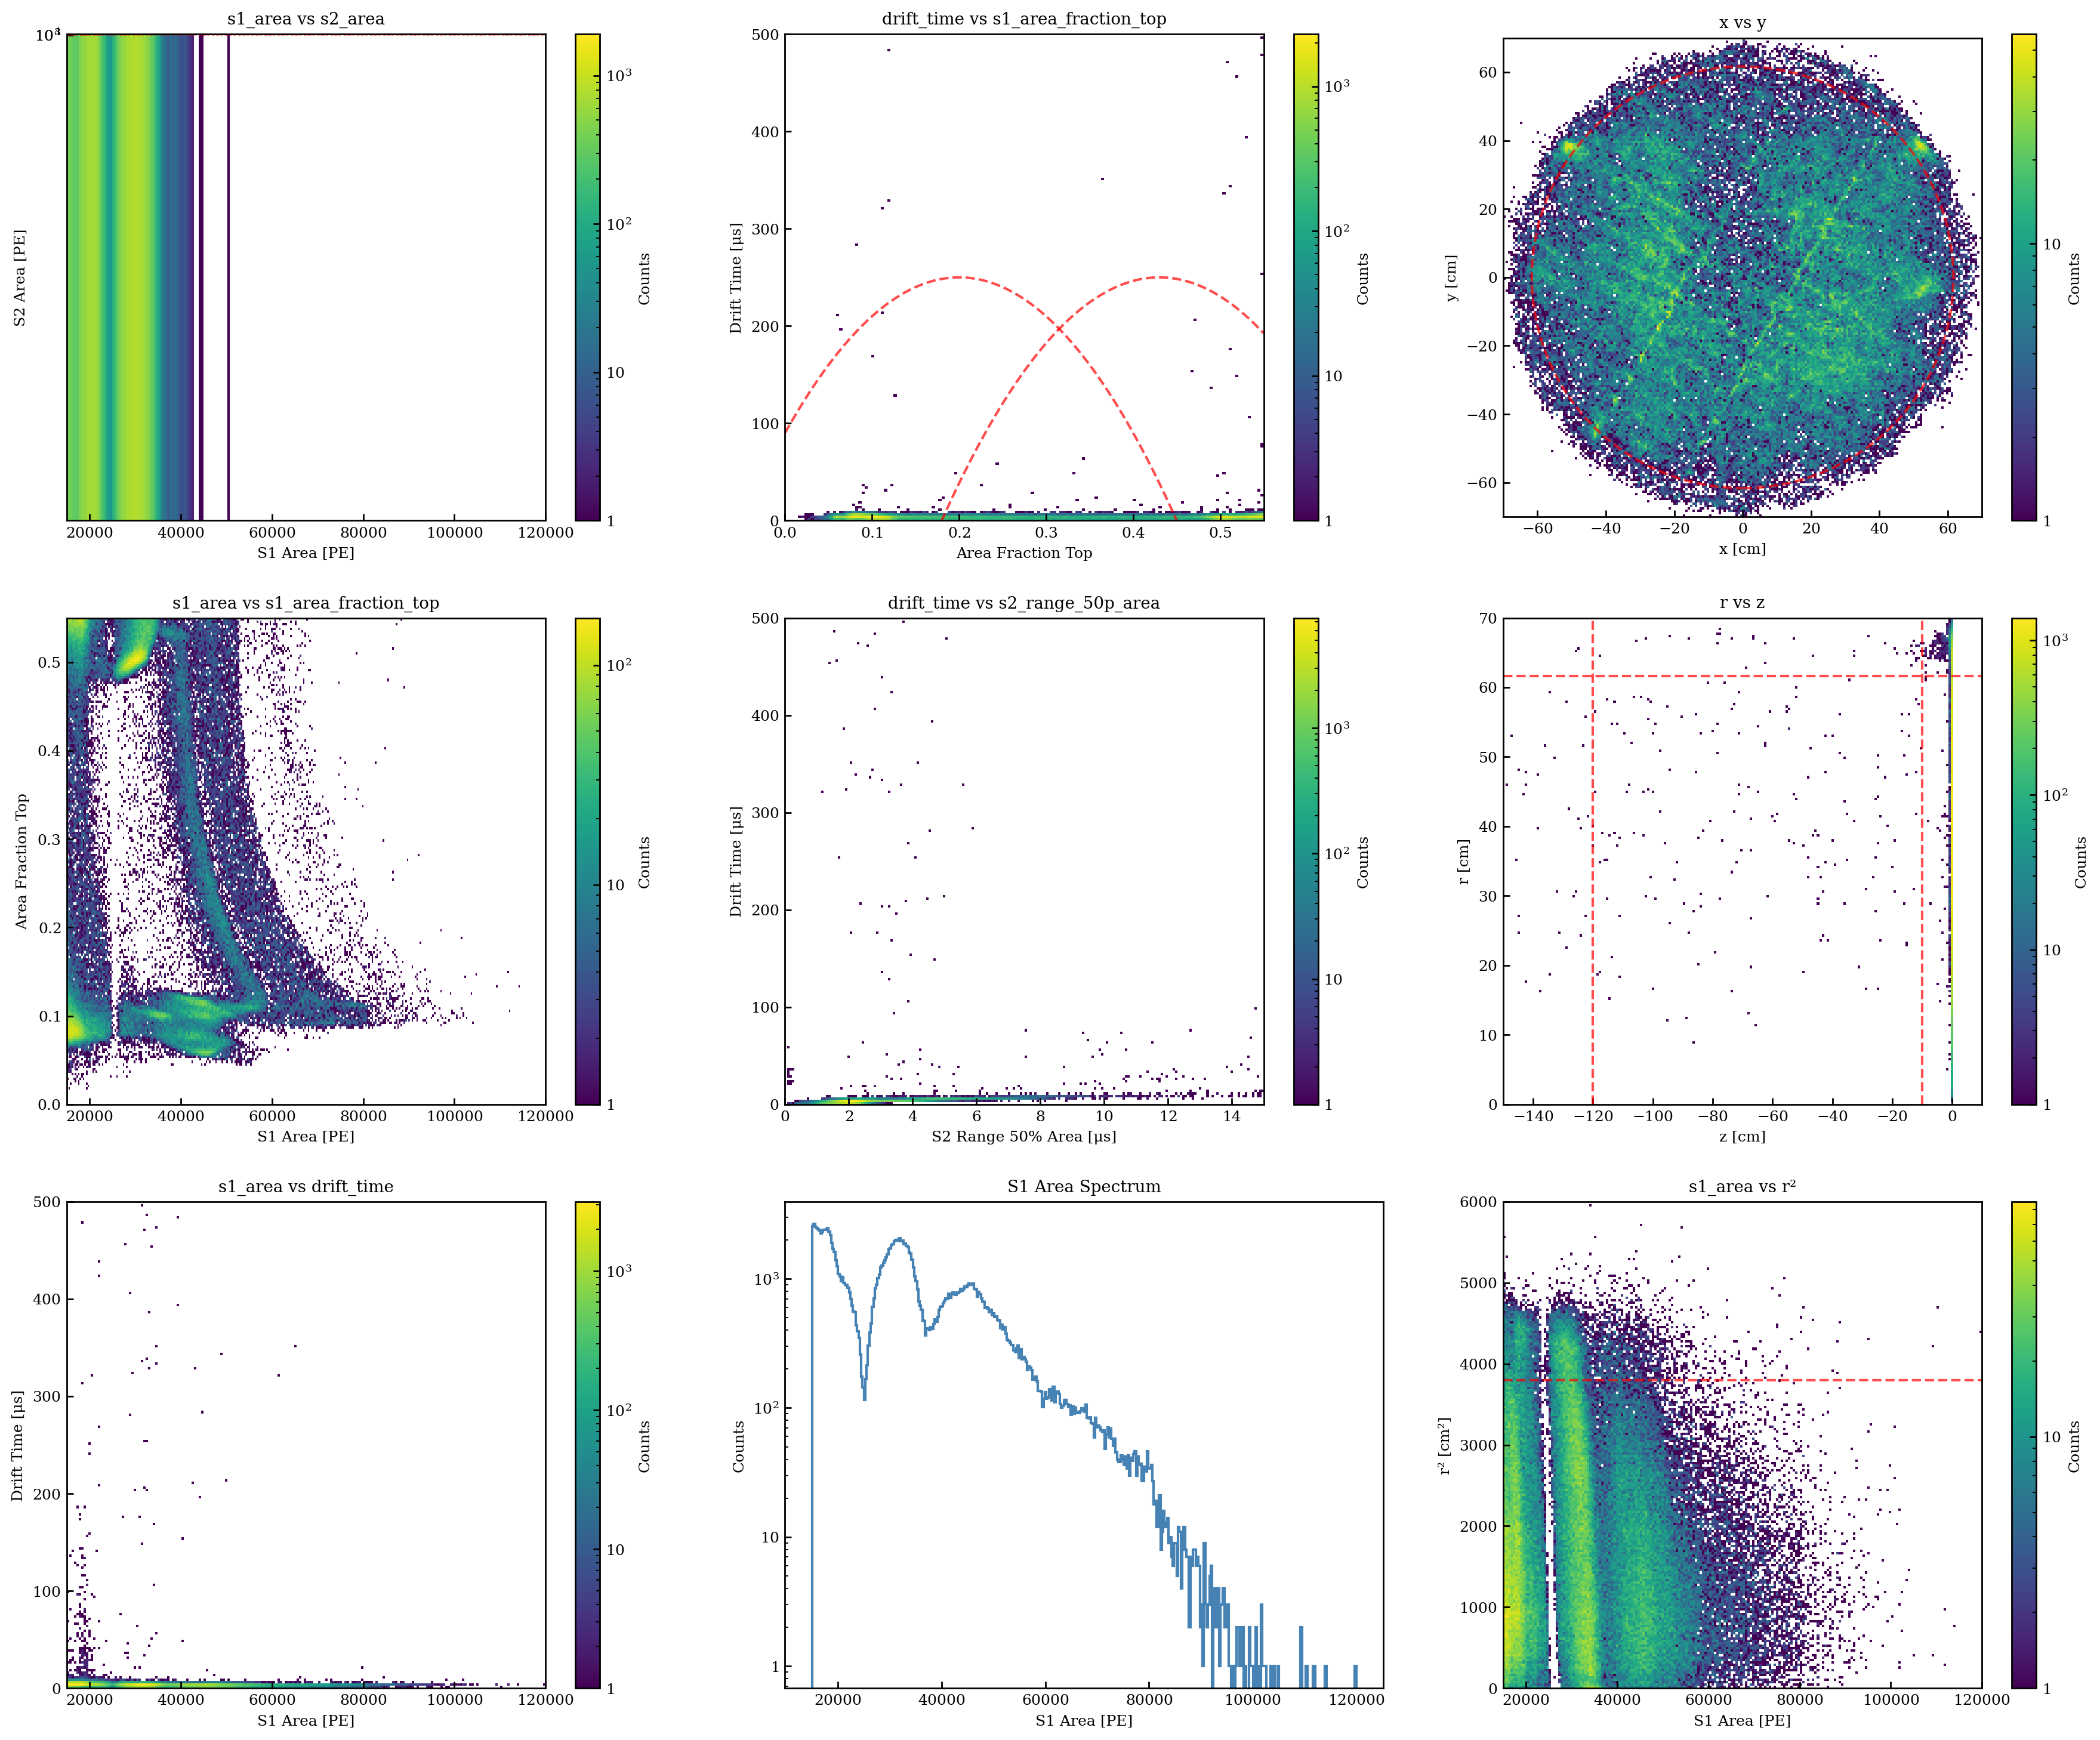

In [27]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  RAW DATA VISUALIZATION — 3×3 diagnostic grid for cut tuning               ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

# Use these plots to manually adjust cut parameters in apply_alpha_cuts() below.
# Current cut boundaries are overlaid as dashed red lines where applicable.

if df is not None:
    fig, axes = plt.subplots(3, 3, figsize=(22, 18))

    # ── Panel 1: s1_area vs s2_area (gamma/electron removal) ──
    ax = axes[0, 0]
    if 's2_area' in df.columns:
        h = ax.hist2d(df['s1_area'], df['s2_area'],
                      bins=[200, 200], range=[[1.5e4, 1.2e5], [0, 5e4]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        # Gamma cut curve: s2 = 3000 * 10^(s1/20000)
        s1_grid = np.linspace(1.5e4, 1.2e5, 500)
        gamma_line = 3.0e3 * np.power(10, s1_grid / 2.0e4)
        ax.plot(s1_grid, np.clip(gamma_line, 0, 5e4), 'r--', lw=1.5, alpha=0.7)
        ax.axhline(y=1.2e4, color='r', ls=':', lw=1, alpha=0.5)
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('S2 Area [PE]')
    ax.set_title('s1_area vs s2_area')
    ax.set_yscale('log')

    # ── Panel 2: drift_time vs s1_area_fraction_top (S1-S2 pair envelope) ──
    ax = axes[0, 1]
    if 'drift_time' in df.columns and 's1_area_fraction_top' in df.columns:
        h = ax.hist2d(df['s1_area_fraction_top'], df['drift_time'] / 1e3,
                      bins=[150, 200], range=[[0.0, 0.55], [0, 500]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        # Overlay polyFunc envelope bounds
        aft_grid = np.linspace(0.0, 0.55, 200)
        dt_lower = polyFunc(aft_grid, [-0.05, 2.0e6, -4.0e6, 0.0]) / 1e3
        dt_upper = polyFunc(aft_grid, [0.18, 2.0e6, -4.0e6, 0.0]) / 1e3
        ax.plot(aft_grid, dt_lower, 'r--', lw=1.5, alpha=0.7)
        ax.plot(aft_grid, dt_upper, 'r--', lw=1.5, alpha=0.7)
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('Area Fraction Top')
    ax.set_ylabel('Drift Time [μs]')
    ax.set_title('drift_time vs s1_area_fraction_top')

    # ── Panel 3: x vs y (spatial distribution) ──
    ax = axes[0, 2]
    if 'x' in df.columns and 'y' in df.columns:
        h = ax.hist2d(df['x'], df['y'],
                      bins=[200, 200], range=[[-70, 70], [-70, 70]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        # FV r boundary circle
        r_fv = np.sqrt(FV_R2_MAX)
        circle = plt.Circle((0, 0), r_fv, fill=False, edgecolor='red',
                            ls='--', lw=1.5, alpha=0.7)
        ax.add_patch(circle)
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('x [cm]')
    ax.set_ylabel('y [cm]')
    ax.set_title('x vs y')
    ax.set_aspect('equal')

    # ── Panel 4: s1_area vs s1_area_fraction_top (alpha band structure) ──
    ax = axes[1, 0]
    if 's1_area_fraction_top' in df.columns:
        h = ax.hist2d(df['s1_area'], df['s1_area_fraction_top'],
                      bins=[300, 200], range=[[1.5e4, 1.2e5], [0.0, 0.55]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('Area Fraction Top')
    ax.set_title('s1_area vs s1_area_fraction_top')

    # ── Panel 5: drift_time vs s2_range_50p_area (unphysical event removal) ──
    ax = axes[1, 1]
    if 'drift_time' in df.columns and 's2_range_50p_area' in df.columns:
        h = ax.hist2d(df['s2_range_50p_area'] / 1e3, df['drift_time'] / 1e3,
                      bins=[200, 200], range=[[0, 15], [0, 500]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        # Unphysical lower bound: dt > polyFunc(s2w, [-2000, -50000, 0, 0.025])
        s2w_grid = np.linspace(0, 15e3, 200)
        dt_lower_s2w = polyFunc(s2w_grid, [-2.0e3, -0.5e5, 0.0, 0.025]) / 1e3
        ax.plot(s2w_grid / 1e3, dt_lower_s2w, 'r--', lw=1.5, alpha=0.7)
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('S2 Range 50% Area [μs]')
    ax.set_ylabel('Drift Time [μs]')
    ax.set_title('drift_time vs s2_range_50p_area')

    # ── Panel 6: r vs z (fiducial volume) ──
    ax = axes[1, 2]
    if 'z' in df.columns and 'r' in df.columns:
        h = ax.hist2d(df['z'], df['r'],
                      bins=[200, 200], range=[[-150, 10], [0, 70]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        # FV boundaries
        ax.axvline(x=FV_Z_MIN, color='red', ls='--', lw=1.5, alpha=0.7)
        ax.axvline(x=FV_Z_MAX, color='red', ls='--', lw=1.5, alpha=0.7)
        ax.axhline(y=np.sqrt(FV_R2_MAX), color='red', ls='--', lw=1.5, alpha=0.7)
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('z [cm]')
    ax.set_ylabel('r [cm]')
    ax.set_title('r vs z')

    # ── Panel 7: s1_area vs drift_time ──
    ax = axes[2, 0]
    if 'drift_time' in df.columns:
        h = ax.hist2d(df['s1_area'], df['drift_time'] / 1e3,
                      bins=[200, 200], range=[[1.5e4, 1.2e5], [0, 500]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('Drift Time [μs]')
    ax.set_title('s1_area vs drift_time')

    # ── Panel 8: S1 area spectrum (1D histogram) ──
    ax = axes[2, 1]
    ax.hist(df['s1_area'], bins=400, range=[1.5e4, 1.2e5],
            histtype='step', color='steelblue', lw=1.5)
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('S1 Area Spectrum')

    # ── Panel 9: s1_area vs r² (radial uniformity) ──
    ax = axes[2, 2]
    if 'r2' in df.columns:
        h = ax.hist2d(df['s1_area'], df['r2'],
                      bins=[200, 200], range=[[1.5e4, 1.2e5], [0, 6000]],
                      cmin=1, norm=LogNorm(), cmap='viridis')
        ax.axhline(y=FV_R2_MAX, color='red', ls='--', lw=1.5, alpha=0.7)
        plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('r² [cm²]')
    ax.set_title('s1_area vs r²')

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_raw_data_overview.png',
                dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('ERROR: df is None — cannot generate plots. Check data loading.')


## Alpha Event Selection Cuts — Per-Cut Tuning

Each cell below is a **self-contained cut**:
- **Parameters** at the top → tune them directly
- **Diagnostic plot** shows the cut boundary overlaid on data
- **Pass/fail stats** printed below the plot

Tune a cut's parameters, re-run that cell, see the effect immediately.
When all cuts look good, run the **Apply All Cuts** cell at the bottom.

| # | Cut | What it removes |
|---|-----|-----------------|
| 1 | S2 vs S1 | Gamma/electron background (low charge yield) |
| 2 | DT vs AFT | Random S1-S2 pairings |
| 3 | AFT lower bound | Bottom-wall BiPo events |
| 4 | DT vs S2 width | Unphysically narrow S2 pulses |
| 5 | alt_s1 | Multi-scatter pileup |
| 6 | z + r² | Non-fiducial volume events |

---


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CUT 1: Gamma/Electron Removal — S2 vs S1 threshold                        ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Rejects gamma/electron background by removing events with low charge yield.
# Events must have S2 below both:
#   1. An exponential boundary:  s2 < C1_S2_SCALE * 10^(s1 / C1_S1_SCALE)
#   2. A hard upper ceiling:     s2 < C1_S2_HARD_MAX
#

# ── Tunable Parameters ──
C1_S2_SCALE   = 3.0e3        # scale factor: s2 = scale * 10^(s1 / s1_scale)
C1_S1_SCALE   = 2.0e4        # S1 scale in the exponential
C1_S2_HARD_MAX = 1.2e4       # absolute S2 upper limit [PE]

# Ensure shared mask dict exists (self-contained cell)
if "cut_masks" not in globals():
    cut_masks = {}

if df is not None and 's2_area' in df.columns:
    # ── Build mask ──
    m1 = pd.Series(True, index=df.index)
    m1 &= (df['s2_area'] < C1_S2_SCALE * np.power(10, df['s1_area'] / C1_S1_SCALE))
    m1 &= (df['s2_area'] < C1_S2_HARD_MAX)
    cut_masks['gamma'] = m1

    # ── Diagnostic plot ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Left: 2D histogram with cut boundaries
    h = ax1.hist2d(df['s1_area'] / 1e3, np.clip(df['s2_area'], 1, 1e9),
                   bins=[150, 150], range=[[10, 120], [1, 5e4]],
                   cmin=1, norm=LogNorm(), cmap='viridis')
    s1_grid = np.logspace(np.log10(1e4), np.log10(2e5), 500)
    gamma_line = C1_S2_SCALE * np.power(10, s1_grid / C1_S1_SCALE)
    ax1.plot(s1_grid / 1e3, np.clip(gamma_line, 0, C1_S2_HARD_MAX),
             'r--', lw=2, label=f's2 = {C1_S2_SCALE:.0e} × 10^(s1/{C1_S1_SCALE:.0e})')
    ax1.axhline(y=C1_S2_HARD_MAX, color='darkred', ls=':', lw=1.5,
                label=f'S2 hard max = {C1_S2_HARD_MAX:.0e} PE')
    ax1.set_xlabel('S1 Area [10$^3$ PE]')
    ax1.set_ylabel('S2 Area [PE]')
    ax1.set_yscale('log')
    ax1.set_title('Cut 1: Gamma/Electron Removal', fontweight='bold')
    ax1.legend(fontsize=8, loc='upper left')
    plt.colorbar(h[3], ax=ax1, label='Counts')

    # Right: 1D S2 area before/after cut
    ax2.hist(np.clip(df['s2_area'], 1, 1e9), bins=200,
             range=[1, 5e4], histtype='step', color='gray', lw=1,
             label=f'Before ({len(df):,})')
    ax2.hist(np.clip(df.loc[m1, 's2_area'], 1, 1e9), bins=200,
             range=[1, 5e4], histtype='step', color='steelblue', lw=1.5,
             label=f'After ({m1.sum():,})')
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    ax2.set_xlabel('S2 Area [PE]')
    ax2.set_ylabel('Counts')
    ax2.set_title('S2 Spectrum — Before vs After Cut 1')
    ax2.legend()

    plt.tight_layout()
    plt.show()

    n_pass = m1.sum()
    n_fail = (~m1).sum()
    print(f"Cut 1 (Gamma): {n_pass:,} / {len(df):,} pass ({100*n_pass/len(df):.1f}%)  —  {n_fail:,} cut")
else:
    print("ERROR: df is None or s2_area column missing")
    cut_masks['gamma'] = pd.Series(True, index=df.index) if df is not None else None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CUT 2: Physical S1-S2 Pair — drift_time vs AFT envelope                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Selects physically-paired S1+S2 events by requiring the drift time to fall
# within an envelope defined as a function of Area Fraction Top (AFT).
# Events outside this band are either S1-only or randomly-paired S2s.
#

# ── Tunable Parameters ──
C2_AFT_LOWER_COEFFS = [-0.05, 2.0e6, -4.0e6, 0.0]  # lower envelope (polyFunc)
C2_AFT_UPPER_COEFFS = [0.18, 2.0e6, -4.0e6, 0.0]   # upper envelope (polyFunc)

# Ensure shared mask dict exists (self-contained cell)
if "cut_masks" not in globals():
    cut_masks = {}

if df is not None and 'drift_time' in df.columns and 's1_area_fraction_top' in df.columns:
    # ── Build mask ──
    dt_lower = polyFunc(df['s1_area_fraction_top'], C2_AFT_LOWER_COEFFS)
    dt_upper = polyFunc(df['s1_area_fraction_top'], C2_AFT_UPPER_COEFFS)
    m2 = (df['drift_time'] > dt_lower) & (df['drift_time'] < dt_upper)
    cut_masks['s1s2_pair'] = m2

    # ── Diagnostic plot ──
    fig, ax = plt.subplots(figsize=(9, 7))

    h = ax.hist2d(df['s1_area_fraction_top'], df['drift_time'] / 1e3,
                   bins=[200, 250], range=[[0, 0.55], [0, 500]],
                   cmin=1, norm=LogNorm(), cmap='viridis')

    aft_grid = np.linspace(0, 0.55, 300)
    dt_lower_curve = polyFunc(aft_grid, C2_AFT_LOWER_COEFFS) / 1e3
    dt_upper_curve = polyFunc(aft_grid, C2_AFT_UPPER_COEFFS) / 1e3

    ax.plot(aft_grid, dt_lower_curve, 'r--', lw=2, label='Lower envelope')
    ax.plot(aft_grid, dt_upper_curve, 'r--', lw=2, label='Upper envelope')
    ax.fill_between(aft_grid, dt_lower_curve, dt_upper_curve,
                    alpha=0.08, color='green', label='Pass region')

    ax.set_xlabel('Area Fraction Top')
    ax.set_ylabel('Drift Time [$\\mu$s]')
    ax.set_title('Cut 2: Physical S1-S2 Pair — Drift Time vs AFT', fontweight='bold')
    ax.legend()
    plt.colorbar(h[3], ax=ax, label='Counts')

    plt.tight_layout()
    plt.show()

    n_pass = m2.sum()
    n_fail = (~m2).sum()
    print(f"Cut 2 (S1-S2 pair): {n_pass:,} / {len(df):,} pass ({100*n_pass/len(df):.1f}%)  —  {n_fail:,} cut")
else:
    print("ERROR: required columns missing (drift_time, s1_area_fraction_top)")
    cut_masks['s1s2_pair'] = pd.Series(True, index=df.index) if df is not None else None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CUT 3: BiPo Rejection — AFT lower bound                                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Rejects BiPo events on the bottom PMT array wall. These events have low
# Area Fraction Top (AFT) because the S1 light is collected mostly by the
# bottom PMTs (wall events near the cathode).
#

# ── Tunable Parameters ──
C3_AFT_MIN = 0.12  # minimum AFT (rejects bottom wall BiPo events)

# Ensure shared mask dict exists (self-contained cell)
if "cut_masks" not in globals():
    cut_masks = {}

if df is not None and 's1_area_fraction_top' in df.columns:
    # ── Build mask ──
    m3 = (df['s1_area_fraction_top'] > C3_AFT_MIN)
    cut_masks['bipo'] = m3

    # ── Diagnostic plot ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Left: 1D AFT histogram
    ax1.hist(df['s1_area_fraction_top'], bins=200, range=[0, 0.55],
             histtype='step', color='gray', lw=1, label=f'All events ({len(df):,})')
    ax1.hist(df.loc[m3, 's1_area_fraction_top'], bins=200, range=[0, 0.55],
             histtype='stepfilled', color='steelblue', alpha=0.5,
             label=f'After AFT cut ({m3.sum():,})')
    ax1.axvline(x=C3_AFT_MIN, color='red', ls='--', lw=2,
                label=f'AFT min = {C3_AFT_MIN}')
    ax1.axvspan(0, C3_AFT_MIN, alpha=0.1, color='red', label='Cut region')
    ax1.set_xlabel('Area Fraction Top')
    ax1.set_ylabel('Counts')
    ax1.set_yscale('log')
    ax1.set_title('Cut 3: BiPo Rejection — AFT Spectrum', fontweight='bold')
    ax1.legend(fontsize=8)

    # Right: S1 vs AFT with cut line
    h = ax2.hist2d(df['s1_area'] / 1e3, df['s1_area_fraction_top'],
                   bins=[200, 150], range=[[10, 120], [0, 0.55]],
                   cmin=1, norm=LogNorm(), cmap='viridis')
    ax2.axhline(y=C3_AFT_MIN, color='red', ls='--', lw=2,
                label=f'AFT > {C3_AFT_MIN}')
    ax2.set_xlabel('S1 Area [10$^3$ PE]')
    ax2.set_ylabel('Area Fraction Top')
    ax2.set_title('S1 Area vs AFT')
    ax2.legend(fontsize=8)
    plt.colorbar(h[3], ax=ax2, label='Counts')

    plt.tight_layout()
    plt.show()

    n_pass = m3.sum()
    n_fail = (~m3).sum()
    print(f"Cut 3 (BiPo): {n_pass:,} / {len(df):,} pass ({100*n_pass/len(df):.1f}%)  —  {n_fail:,} cut")
else:
    print("ERROR: s1_area_fraction_top column missing")
    cut_masks['bipo'] = pd.Series(True, index=df.index) if df is not None else None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CUT 4: Unphysical Event Removal — drift_time vs S2 width                   ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Removes events with unphysically narrow S2 pulses for their drift time.
# A lower bound polynomial excludes events where the S2 is too narrow —
# such narrow pulses are usually single-electron backgrounds, not real alphas.
#

# ── Tunable Parameters ──
C4_S2W_LOWER_COEFFS = [-2.0e3, -0.5e5, 0.0, 0.025]  # lower bound (polyFunc)

# Ensure shared mask dict exists (self-contained cell)
if "cut_masks" not in globals():
    cut_masks = {}

if df is not None and 'drift_time' in df.columns and 's2_range_50p_area' in df.columns:
    # ── Build mask ──
    dt_lower_s2w = polyFunc(df['s2_range_50p_area'], C4_S2W_LOWER_COEFFS)
    m4 = (df['drift_time'] > dt_lower_s2w)
    cut_masks['unphysical'] = m4

    # ── Diagnostic plot ──
    fig, ax = plt.subplots(figsize=(9, 7))

    h = ax.hist2d(df['s2_range_50p_area'] / 1e3, df['drift_time'] / 1e3,
                   bins=[200, 250], range=[[0, 15], [0, 500]],
                   cmin=1, norm=LogNorm(), cmap='viridis')

    s2w_grid = np.linspace(0, 15e3, 300)
    dt_bound = polyFunc(s2w_grid, C4_S2W_LOWER_COEFFS) / 1e3

    ax.plot(s2w_grid / 1e3, dt_bound, 'r--', lw=2, label='Lower bound (drift_time > poly)')
    ax.fill_between(s2w_grid / 1e3, dt_bound, 500,
                    alpha=0.08, color='green', label='Pass region')

    ax.set_xlabel('S2 Range 50% Area [$\\mu$s]')
    ax.set_ylabel('Drift Time [$\\mu$s]')
    ax.set_title('Cut 4: Unphysical Event Removal — Drift Time vs S2 Width', fontweight='bold')
    ax.legend()
    plt.colorbar(h[3], ax=ax, label='Counts')

    plt.tight_layout()
    plt.show()

    n_pass = m4.sum()
    n_fail = (~m4).sum()
    print(f"Cut 4 (Unphysical): {n_pass:,} / {len(df):,} pass ({100*n_pass/len(df):.1f}%)  —  {n_fail:,} cut")
else:
    print("ERROR: required columns missing (drift_time, s2_range_50p_area)")
    cut_masks['unphysical'] = pd.Series(True, index=df.index) if df is not None else None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CUT 5: Multi-Scatter Rejection — alt_s1 in odd region                      ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Removes multi-scatter events identified by significant alternate S1 signals
# in a specific region of S1-S2 space ("odd MS region").
# These are likely simultaneous interactions (pileup/multiple scatters).
#

# ── Tunable Parameters ──
C5_MS_S2_MIN     = 6.0e4      # odd-MS s2 lower bound [PE]
C5_MS_S2_MAX     = 2.0e6      # odd-MS s2 upper bound [PE]
C5_MS_S1_MIN     = 0.0        # odd-MS s1 lower bound [PE]
C5_MS_S1_MAX     = 5.9e4      # odd-MS s1 upper bound [PE]
C5_MS_ALT_S1_MIN = 70.0       # odd-MS alt_s1 threshold [PE]

# Ensure shared mask dict exists (self-contained cell)
if "cut_masks" not in globals():
    cut_masks = {}

if df is not None and all(c in df.columns for c in ['s2_area', 's1_area', 'alt_s1_area']):
    # ── Build mask ──
    odd_ms = (
        (df['s2_area'] > C5_MS_S2_MIN) &
        (df['s2_area'] < C5_MS_S2_MAX) &
        (df['s1_area'] > C5_MS_S1_MIN) &
        (df['s1_area'] < C5_MS_S1_MAX) &
        (df['alt_s1_area'].notna()) &
        (df['alt_s1_area'] > C5_MS_ALT_S1_MIN)
    )
    m5 = ~odd_ms
    cut_masks['multiscatter'] = m5

    # ── Diagnostic plot ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Left: S2 vs S1 with odd-MS region highlighted
    h = ax1.hist2d(df['s1_area'] / 1e3, df['s2_area'] / 1e3,
                   bins=[150, 150], range=[[10, 120], [0, 5e4]],
                   cmin=1, norm=LogNorm(), cmap='viridis')
    # Highlight the odd-MS region
    rect = plt.Rectangle(
        (C5_MS_S1_MIN / 1e3, C5_MS_S2_MIN / 1e3),
        (C5_MS_S1_MAX - C5_MS_S1_MIN) / 1e3,
        (C5_MS_S2_MAX - C5_MS_S2_MIN) / 1e3,
        fill=False, edgecolor='red', ls='--', lw=2, label='Odd MS region'
    )
    ax1.add_patch(rect)
    # Overlay rejected events
    ax1.scatter(df.loc[odd_ms, 's1_area'] / 1e3,
                df.loc[odd_ms, 's2_area'] / 1e3,
                s=2, color='red', alpha=0.5, label=f'MS rejected ({odd_ms.sum():,})')
    ax1.set_xlabel('S1 Area [10$^3$ PE]')
    ax1.set_ylabel('S2 Area [10$^3$ PE]')
    ax1.set_title('Cut 5: Multi-Scatter Rejection', fontweight='bold')
    ax1.legend(fontsize=7, loc='upper right')
    plt.colorbar(h[3], ax=ax1, label='Counts')

    # Right: alt_s1 distribution for events inside vs outside odd-MS region
    in_region = (
        (df['s2_area'] > C5_MS_S2_MIN) & (df['s2_area'] < C5_MS_S2_MAX) &
        (df['s1_area'] > C5_MS_S1_MIN) & (df['s1_area'] < C5_MS_S1_MAX)
    )
    ax2.hist(df.loc[in_region & df['alt_s1_area'].notna(), 'alt_s1_area'],
             bins=200, range=[0, 500], histtype='step', color='gray', lw=1,
             label=f'In odd-MS region ({in_region.sum():,})')
    ax2.hist(df.loc[in_region & odd_ms, 'alt_s1_area'],
             bins=200, range=[0, 500], histtype='stepfilled',
             color='red', alpha=0.5, label=f'Rejected (alt_s1 > {C5_MS_ALT_S1_MIN:.0f})')
    ax2.axvline(x=C5_MS_ALT_S1_MIN, color='red', ls='--', lw=1.5,
                label=f'alt_s1 = {C5_MS_ALT_S1_MIN:.0f}')
    ax2.set_xlabel('Alternate S1 Area [PE]')
    ax2.set_ylabel('Counts')
    ax2.set_yscale('log')
    ax2.set_title('alt_s1 in Odd-MS Region')
    ax2.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    n_pass = m5.sum()
    n_fail = (~m5).sum()
    print(f"Cut 5 (Multi-scatter): {n_pass:,} / {len(df):,} pass ({100*n_pass/len(df):.1f}%)  —  {n_fail:,} cut")
else:
    print("ERROR: required columns missing (s2_area, s1_area, alt_s1_area)")
    cut_masks['multiscatter'] = pd.Series(True, index=df.index) if df is not None else None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CUT 6: Fiducial Volume — z and r²                                          ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Restricts to events within the fiducial volume:
#   C6_FV_Z_MIN < z < C6_FV_Z_MAX    (vertical)
#   r² < C6_FV_R2_MAX                (radial)
#

# ── Tunable Parameters ──
C6_FV_Z_MIN  = -120.0  # cm — fiducial bottom
C6_FV_Z_MAX  = -10.0   # cm — fiducial top
C6_FV_R2_MAX = 3800.0  # cm² — fiducial r² max (~61.6 cm)

# Ensure shared mask dict exists (self-contained cell)
if "cut_masks" not in globals():
    cut_masks = {}

if df is not None:
    # ── Build mask ──
    m6 = pd.Series(True, index=df.index)
    if 'z' in df.columns:
        m6 &= (df['z'] > C6_FV_Z_MIN) & (df['z'] < C6_FV_Z_MAX)
    if 'r2' in df.columns:
        m6 &= (df['r2'] < C6_FV_R2_MAX)
    elif 'x' in df.columns and 'y' in df.columns:
        m6 &= (df['x']**2 + df['y']**2 < C6_FV_R2_MAX)
    cut_masks['fv'] = m6

    # ── Diagnostic plot ──
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))

    # Panel 1: z histogram
    ax = axes[0]
    if 'z' in df.columns:
        ax.hist(df['z'], bins=200, range=[-155, 10],
                histtype='step', color='gray', lw=1, label=f'All events ({len(df):,})')
        ax.hist(df.loc[m6, 'z'], bins=200, range=[-155, 10],
                histtype='stepfilled', color='steelblue', alpha=0.5,
                label=f'After FV ({m6.sum():,})')
        ax.axvline(x=C6_FV_Z_MIN, color='red', ls='--', lw=2, label=f'z > {C6_FV_Z_MIN}')
        ax.axvline(x=C6_FV_Z_MAX, color='red', ls='--', lw=2, label=f'z < {C6_FV_Z_MAX}')
    ax.set_xlabel('z [cm]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('z Distribution', fontweight='bold')
    ax.legend(fontsize=7)

    # Panel 2: r² histogram
    ax = axes[1]
    r2_col = 'r2' if 'r2' in df.columns else None
    if r2_col:
        ax.hist(df[r2_col], bins=200, range=[0, 6000],
                histtype='step', color='gray', lw=1, label=f'All events ({len(df):,})')
        ax.hist(df.loc[m6, r2_col], bins=200, range=[0, 6000],
                histtype='stepfilled', color='steelblue', alpha=0.5,
                label=f'After FV ({m6.sum():,})')
        ax.axvline(x=C6_FV_R2_MAX, color='red', ls='--', lw=2,
                   label=f'r² < {C6_FV_R2_MAX:.0f}')
        r_fv = np.sqrt(C6_FV_R2_MAX)
        ax.text(0.98, 0.95, f'r = {r_fv:.1f} cm', transform=ax.transAxes,
                ha='right', fontsize=9, va='top')
    ax.set_xlabel('r² [cm²]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('r² Distribution', fontweight='bold')
    ax.legend(fontsize=7)

    # Panel 3: x vs y (spatial) with pass/fail
    ax = axes[2]
    if 'x' in df.columns and 'y' in df.columns:
        ax.hist2d(df.loc[~m6, 'x'], df.loc[~m6, 'y'],
                  bins=[150, 150], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=LogNorm(), cmap='viridis', alpha=0.6)
        ax.hist2d(df.loc[m6, 'x'], df.loc[m6, 'y'],
                  bins=[150, 150], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=LogNorm(), cmap='viridis')
        r_fv = np.sqrt(C6_FV_R2_MAX)
        circle = plt.Circle((0, 0), r_fv, fill=False, edgecolor='red',
                            ls='--', lw=2, label=f'r = {r_fv:.1f} cm')
        ax.add_patch(circle)
    ax.set_xlabel('x [cm]')
    ax.set_ylabel('y [cm]')
    ax.set_aspect('equal')
    ax.set_title('Spatial Distribution', fontweight='bold')
    ax.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

    n_pass = m6.sum()
    n_fail = (~m6).sum()
    print(f"Cut 6 (Fiducial Volume): {n_pass:,} / {len(df):,} pass ({100*n_pass/len(df):.1f}%)  —  {n_fail:,} cut")
else:
    print("ERROR: df is None")
    cut_masks['fv'] = pd.Series(True, index=df.index) if df is not None else None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  APPLY ALL CUTS — combine individual masks and produce df_alpha             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝
#
# Combines all 6 cut masks and produces the final alpha-selected DataFrame.
# Run this cell after you are satisfied with the individual cut parameters.

# Ensure shared mask dict exists
if "cut_masks" not in globals():
    cut_masks = {}
# ── Combine all masks ──


## Mask Generation

Following the production code's `gen_masks()` convention, define:
- `mask_base` — all events passing alpha cuts
- `mask_final_FV` — base + fiducial volume
- Xenon properties for rate normalization


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  MASK GENERATION — equivalent to python_config.gen_masks()                ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None:
    # All alpha-cut events are our "base" sample
    mask_base = pd.Series(True, index=df_alpha.index)

    # Final FV mask — already applied in alpha cuts, but re-compute for safety
    mask_final_FV = mask_base.copy()
    if 'z' in df_alpha.columns:
        mask_final_FV &= (df_alpha['z'] > FV_Z_MIN) & (df_alpha['z'] < FV_Z_MAX)
    if 'r2' in df_alpha.columns:
        mask_final_FV &= (df_alpha['r2'] < FV_R2_MAX)

    # Compute fiducial mass
    # Fiducial volume = cylinder: π * R² * Δz
    fid_r_max = np.sqrt(FV_R2_MAX)  # cm
    fid_z_span = FV_Z_MAX - FV_Z_MIN  # cm
    XeFidVol = np.pi * fid_r_max**2 * fid_z_span  # cm³
    XeFidMass = XeFidVol * XE_DENSITY_KG_CM3  # kg

    mask_dict = {
        'mask_base': mask_base.values if hasattr(mask_base, 'values') else mask_base,
        'mask_final_FV': mask_final_FV.values if hasattr(mask_final_FV, 'values') else mask_final_FV,
        'XeDensity': XE_DENSITY_KG_CM3,
        'XeFidVol': XeFidVol,
        'XeFidMass': XeFidMass,
    }

    # For rate normalization: ratio of events with valid S2 to total FV events
    if 's2_area' in df_alpha.columns:
        n_total_fv = mask_final_FV.sum()
        n_valid_s2 = (mask_final_FV & (df_alpha['s2_area'] > 0)).sum()
        mask_dict['validS1S2Ratio'] = n_valid_s2 / max(n_total_fv, 1) if n_total_fv > 0 else 1.0
    else:
        mask_dict['validS1S2Ratio'] = 1.0

    print("Mask dictionary:")
    for key, val in mask_dict.items():
        if 'mask' in key:
            print(f"  {key}: {np.sum(val):,} events")
        else:
            print(f"  {key}: {val}")

    print(f"
Fiducial volume: {XeFidVol:.1f} cm³ = {XeFidVol*1e-3:.1f} L")
    print(f"Fiducial mass:   {XeFidMass:.2f} kg")
    print(f"validS1S2Ratio:  {mask_dict['validS1S2Ratio']:.3f}")
else:
    print("ERROR: df_alpha is None")
    mask_dict = None


## Exploratory Plots — S1+S2 Data Overview

6-panel diagnostic plot to verify the data quality and alpha selection:
1. S1 area spectrum (log)
2. S1 area vs AFT — the key diagnostic plot showing alpha bands
3. S1 area vs drift time
4. S2 area vs S1 area — gamma/alpha separation
5. S1 area vs r² — radial uniformity
6. z distribution


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  EXPLORATORY PLOTS — 6-panel S1+S2 data overview                          ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None:
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    CMAP = 'plasma'

    # 1. S1 area spectrum
    ax = axes[0, 0]
    ax.hist(df_alpha['s1_area'], bins=400, range=[1.5e4, 1.2e5],
            histtype='step', color='steelblue', lw=1.5)
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('S1 Area Spectrum (alpha candidates)')

    # 2. S1 area vs AFT — THE key plot
    ax = axes[0, 1]
    h = ax.hist2d(df_alpha['s1_area'], df_alpha['s1_area_fraction_top'],
                  bins=[300, 200], range=[[1.5e4, 1.0e5], [0.0, 0.55]],
                  cmin=1, norm=LogNorm(), cmap=CMAP)
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('Area Fraction Top')
    ax.set_title('S1 Area vs AFT')

    # 3. S1 area vs drift time
    ax = axes[0, 2]
    if 'drift_time' in df_alpha.columns:
        h = ax.hist2d(df_alpha['s1_area'], df_alpha['drift_time'] / 1e3,
                      bins=[300, 200], range=[[1.5e4, 1.0e5], [0, 400]],
                      cmin=1, norm=LogNorm(), cmap=CMAP)
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.set_xlabel('S1 Area [PE]')
        ax.set_ylabel('Drift Time [μs]')
        ax.set_title('S1 Area vs Drift Time')
    else:
        ax.text(0.5, 0.5, 'No drift_time', ha='center', va='center',
                transform=ax.transAxes)

    # 4. S2 vs S1 — gamma/alpha separation
    ax = axes[1, 0]
    if 's2_area' in df_alpha.columns:
        h = ax.hist2d(df_alpha['s1_area'], df_alpha['s2_area'],
                      bins=[300, 200], range=[[1.5e4, 1.0e5], [0, 5e4]],
                      cmin=1, norm=LogNorm(), cmap=CMAP)
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.set_xlabel('S1 Area [PE]')
        ax.set_ylabel('S2 Area [PE]')
        ax.set_title('S2 vs S1 — Gamma/Alpha Separation')
        ax.set_yscale('log')
    else:
        ax.text(0.5, 0.5, 'No s2_area', ha='center', va='center',
                transform=ax.transAxes)

    # 5. S1 area vs r² — radial uniformity
    ax = axes[1, 1]
    if 'r2' in df_alpha.columns:
        h = ax.hist2d(df_alpha['s1_area'], df_alpha['r2'],
                      bins=[300, 200], range=[[1.5e4, 1.0e5], [0, 4000]],
                      cmin=1, norm=LogNorm(), cmap=CMAP)
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.axvline(x=FV_R2_MAX, color='red', ls='--', lw=1, alpha=0.5)
        ax.set_xlabel('S1 Area [PE]')
        ax.set_ylabel('r² [cm²]')
        ax.set_title('S1 Area vs r² — Radial Uniformity')
    else:
        ax.text(0.5, 0.5, 'No r²', ha='center', va='center',
                transform=ax.transAxes)

    # 6. z distribution
    ax = axes[1, 2]
    if 'z' in df_alpha.columns:
        ax.hist(df_alpha['z'], bins=100, range=[-150, 0],
                histtype='step', color='steelblue', lw=1.5)
        ax.axvline(x=FV_Z_MIN, color='red', ls='--', lw=1, alpha=0.5)
        ax.axvline(x=FV_Z_MAX, color='red', ls='--', lw=1, alpha=0.5)
        ax.set_xlabel('z [cm]')
        ax.set_ylabel('Counts')
        ax.set_yscale('log')
        ax.set_title('z Distribution (with FV limits)')
    else:
        ax.text(0.5, 0.5, 'No z', ha='center', va='center',
                transform=ax.transAxes)

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_overview.png',
                dpi=150, bbox_inches='tight')
    plt.show()


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  SAVE PROCESSED DATA                                                       ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

S1S2_ALPHA_PATH = "/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_alpha_events.pkl"
if df_alpha is not None:
    df_alpha.to_pickle(S1S2_ALPHA_PATH)
    print(f"Saved {len(df_alpha):,} alpha-candidate events to:")
    print(f"  {S1S2_ALPHA_PATH}")
    print(f"
To reload: df_alpha = pd.read_pickle('{S1S2_ALPHA_PATH}')")


---
# Correction Derivation

This is the core of the S1S2 analysis. We correct the S1 area for two effects:

## Correction 1 — AFT (z-position) Correction

The S1 light collection efficiency varies with the event's depth in the TPC.
AFT (Area Fraction Top) is a proxy for z-position: events near the top PMT array
have higher AFT, events near the bottom have lower AFT.

We fit the curved alpha band centerline in area-vs-AFT space with `exp2Func`,
then normalize all areas to a reference AFT (0.30).

```
s1_corr1 = s1_area × area_ref / exp2Func(AFT, *fit_params)
```

The fit is performed on a manually-bracketed band of Rn-222/Po-218 alpha events.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CORRECTION 1: AFT (z-position) — band selection and fit                  ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and mask_dict is not None:

    # ── Manual band selection: bracket the Rn-222 / Po-218 / Po-214 band ──
    # These are exp2Func parameters that define upper/lower boundaries
    # that bracket the alpha band in area-vs-AFT space.
    # Format: [a, b, c, d] for exp2Func(AFT, a, b, c, d)

    selAFTupperBound = [30.0e4, -0.15, -0.1, 3.8e4]
    selAFTlowerBound = [30.0e4, -0.12, -0.1, 5.8e4]

    # Create band selection mask
    mask_fv = mask_dict['mask_final_FV']
    mask_amp_AFT_sel = (
        mask_fv &
        (exp2Func(df_alpha['s1_area_fraction_top'], *selAFTupperBound) <= df_alpha['s1_area']) &
        (df_alpha['s1_area'] < exp2Func(df_alpha['s1_area_fraction_top'], *selAFTlowerBound))
    )

    print(f"Events in AFT band for Correction 1 fit: {mask_amp_AFT_sel.sum():,}")

    # ── Fit exp2Func to the band centerline ──
    # Flatten the selection: take all events in band, fit area vs AFT
    x_data = df_alpha.loc[mask_amp_AFT_sel, 's1_area'].values.astype(np.float64)
    y_data = df_alpha.loc[mask_amp_AFT_sel, 's1_area_fraction_top'].values.astype(np.float64)

    # Initial guess: midpoint of upper/lower bounds
    p0_aft = (np.array(selAFTupperBound) + np.array(selAFTlowerBound)) / 2.0

    # Use iminuit for the fit (matches production code)
    cost_aft = iminuit.cost.LeastSquares(y_data, x_data, np.ones(len(x_data)), exp2Func)
    minuit_aft = Minuit(cost_aft, *p0_aft)
    opt_aft = minuit_aft.migrad()

    S1_areaCorr1Pars_AFT = [val for val in opt_aft.values]
    S1_areaCorr1Errs_AFT = [err for err in opt_aft.errors]

    print("
Correction 1 (AFT) fit result:")
    print(f"  a = {S1_areaCorr1Pars_AFT[0]:.2e} ± {S1_areaCorr1Errs_AFT[0]:.2e}")
    print(f"  b = {S1_areaCorr1Pars_AFT[1]:.6f} ± {S1_areaCorr1Errs_AFT[1]:.6f}")
    print(f"  c = {S1_areaCorr1Pars_AFT[2]:.6f} ± {S1_areaCorr1Errs_AFT[2]:.6f}")
    print(f"  d = {S1_areaCorr1Pars_AFT[3]:.2e} ± {S1_areaCorr1Errs_AFT[3]:.2e}")
    print(f"
  Valid: {opt_aft.valid}, fval: {opt_aft.fval:.1f}")
else:
    print("ERROR: df_alpha or mask_dict is None")
    S1_areaCorr1Pars_AFT = [3e5, -0.13, -0.1, 4.5e4]
    S1_areaCorr1Errs_AFT = [0, 0, 0, 0]


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  APPLY CORRECTION 1 → s1_corr1                                            ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

AFT_REF = 0.30  # reference AFT value

if df_alpha is not None:
    # Correction: s1_corr1 = s1_area * exp2Func(AFT_ref) / exp2Func(AFT)
    s1_ref_aft = exp2Func(AFT_REF, *S1_areaCorr1Pars_AFT)

    df_alpha['s1_corr1'] = (
        df_alpha['s1_area'].values.astype(np.float64)
        * s1_ref_aft
        / exp2Func(df_alpha['s1_area_fraction_top'].values.astype(np.float64),
                   *S1_areaCorr1Pars_AFT)
    )

    print(f"Correction 1 applied (AFT → z correction)")
    print(f"  Reference AFT: {AFT_REF}")
    print(f"  Reference area at AFT={AFT_REF}: {s1_ref_aft:.0f} PE")
    print(f"  s1_corr1 range: [{df_alpha['s1_corr1'].min():.0f}, {df_alpha['s1_corr1'].max():.0f}] PE")
    print(f"  Correction factor range: [{df_alpha['s1_area'].min()/df_alpha['s1_corr1'].max():.3f}, "
          f"{df_alpha['s1_area'].max()/df_alpha['s1_corr1'].min():.3f}]")


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CORRECTION 1 PLOTS — before/after comparison                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None:
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # ── Panel 1: Raw S1 area vs AFT with selection bands ──
    ax = axes[0]
    h = ax.hist2d(df_alpha['s1_area'], df_alpha['s1_area_fraction_top'],
                  bins=[300, 200], range=[[1.5e4, 1.0e5], [0.0, 0.55]],
                  cmin=1, norm=LogNorm(), cmap='plasma')
    plt.colorbar(h[3], ax=ax, label='Counts')

    aft_fine = np.linspace(0.05, 0.55, 500)
    ax.plot(exp2Func(aft_fine, *selAFTupperBound), aft_fine,
            '--', color='orange', lw=2, alpha=0.7, label='AFT band (upper/lower)')
    ax.plot(exp2Func(aft_fine, *selAFTlowerBound), aft_fine,
            '--', color='orange', lw=2, alpha=0.7)
    ax.plot(exp2Func(aft_fine, *S1_areaCorr1Pars_AFT), aft_fine,
            '-', color='red', lw=3, label='Fitted centerline')
    ax.set_xlabel('S1 Area [PE]')
    ax.set_ylabel('Area Fraction Top')
    ax.set_title('RAW S1 Area vs AFT + Band Fit')
    ax.legend(fontsize=9)

    # ── Panel 2: Corrected s1_corr1 vs AFT ──
    ax = axes[1]
    h = ax.hist2d(df_alpha['s1_corr1'], df_alpha['s1_area_fraction_top'],
                  bins=[300, 200], range=[[1.5e4, 1.0e5], [0.0, 0.55]],
                  cmin=1, norm=LogNorm(), cmap='plasma')
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.axvline(x=s1_ref_aft, color='red', lw=2, ls='-',
               label=f'Ref = {s1_ref_aft:.0f} PE')
    ax.set_xlabel('s1_corr1 (AFT-corrected) [PE]')
    ax.set_ylabel('Area Fraction Top')
    ax.set_title('AFTER AFT Correction — s1_corr1 vs AFT')
    ax.legend(fontsize=9)

    # ── Panel 3: 1D comparison — raw vs corrected ──
    ax = axes[2]
    ax.hist(df_alpha['s1_area'], bins=300, range=[2e4, 9e4],
            histtype='step', color='gray', lw=1.5, label='Raw S1 area', density=True)
    ax.hist(df_alpha['s1_corr1'], bins=300, range=[2e4, 9e4],
            histtype='step', color='red', lw=2, label='s1_corr1 (AFT-corrected)', density=True)
    ax.set_xlabel('Area [PE]')
    ax.set_ylabel('Normalized Counts')
    ax.set_title('1D Spectrum: Raw vs AFT-Corrected')
    ax.set_yscale('log')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_correction1_aft.png',
                dpi=150, bbox_inches='tight')
    plt.show()


## Correction 2 — Radial (r²) Correction

After AFT correction, there is residual radial dependence: events near the TPC
wall have slightly lower light collection than events near the center.

We fit a linear function of r² to the AFT-corrected S1 area:
```
s1_corr2 = s1_corr1 × area_ref / linearFunc(r², *fit_params)
```

where `linearFunc(r², a, b) = a * (1 + b * r²)`.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CORRECTION 2: Radial (r²) — band selection and fit                       ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and mask_dict is not None and 'r2' in df_alpha.columns:

    # ── Manual band selection for Correction 2 ──
    selR2upperBound = [4.0E4, -1.4]   # linearFunc params
    selR2lowerBound = [5.8E4, -1.4]

    mask_fv = mask_dict['mask_final_FV']
    mask_amp_r2_sel = (
        mask_fv &
        (linearFunc(df_alpha['r2'], *selR2upperBound) <= df_alpha['s1_corr1']) &
        (df_alpha['s1_corr1'] < linearFunc(df_alpha['r2'], *selR2lowerBound))
    )

    print(f"Events in r² band for Correction 2 fit: {mask_amp_r2_sel.sum():,}")

    # ── Fit linearFunc to s1_corr1 vs r² ──
    x_data = df_alpha.loc[mask_amp_r2_sel, 's1_corr1'].values.astype(np.float64)
    y_data = df_alpha.loc[mask_amp_r2_sel, 'r2'].values.astype(np.float64)

    p0_r2 = (np.array(selR2upperBound) + np.array(selR2lowerBound)) / 2.0

    cost_r2 = iminuit.cost.LeastSquares(y_data, x_data, np.ones(len(x_data)), linearFunc)
    minuit_r2 = Minuit(cost_r2, *p0_r2)
    opt_r2 = minuit_r2.migrad()

    S1_areaCorr2Pars = [val for val in opt_r2.values]
    S1_areaCorr2Errs = [err for err in opt_r2.errors]

    print("
Correction 2 (r²) fit result:")
    print(f"  a = {S1_areaCorr2Pars[0]:.2e} ± {S1_areaCorr2Errs[0]:.2e}")
    print(f"  b = {S1_areaCorr2Pars[1]:.6e} ± {S1_areaCorr2Errs[1]:.6e}")
    print(f"
  Valid: {opt_r2.valid}, fval: {opt_r2.fval:.1f}")

    # ── Apply Correction 2 → s1_corrF ──
    df_alpha['s1_corrF'] = (
        df_alpha['s1_corr1'].values.astype(np.float64)
        * S1_areaCorr2Pars[0]
        / linearFunc(df_alpha['r2'].values.astype(np.float64), *S1_areaCorr2Pars)
    )

    R2_REF = 0.0  # reference at r=0 (TPC center)
    s1_ref_r2 = linearFunc(R2_REF, *S1_areaCorr2Pars)
    print(f"
Correction 2 applied (r² → FV correction)")
    print(f"  Reference r²: {R2_REF} cm²")
    print(f"  Reference area at r²={R2_REF}: {s1_ref_r2:.0f} PE")
    print(f"  s1_corrF range: [{df_alpha['s1_corrF'].min():.0f}, {df_alpha['s1_corrF'].max():.0f}] PE")
else:
    print("ERROR: Cannot run Correction 2 — missing data or r2 column")
    print(f"  df_alpha is None: {df_alpha is None}")
    if df_alpha is not None:
        print(f"  'r2' in columns: {'r2' in df_alpha.columns}")
    S1_areaCorr2Pars = [5e4, -1e-4]
    S1_areaCorr2Errs = [0, 0]


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CORRECTION 2 PLOTS — before (s1_corr1) vs after (s1_corrF)              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and 's1_corrF' in df_alpha.columns:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # ── Panel 1: s1_corr1 vs r² with fit ──
    ax = axes[0, 0]
    h = ax.hist2d(df_alpha['s1_corr1'], df_alpha['r2'],
                  bins=[300, 200], range=[[2e4, 8e4], [0, 4000]],
                  cmin=1, norm=LogNorm(), cmap='plasma')
    plt.colorbar(h[3], ax=ax, label='Counts')
    r2_fine = np.linspace(0, 4000, 500)
    ax.plot(linearFunc(r2_fine, *selR2upperBound), r2_fine,
            '--', color='orange', lw=1.5, alpha=0.7, label='r² band')
    ax.plot(linearFunc(r2_fine, *selR2lowerBound), r2_fine,
            '--', color='orange', lw=1.5, alpha=0.7)
    ax.plot(linearFunc(r2_fine, *S1_areaCorr2Pars), r2_fine,
            '-', color='red', lw=2.5, label='Fitted')
    ax.set_xlabel('s1_corr1 [PE]')
    ax.set_ylabel('r² [cm²]')
    ax.set_title('AFT-Corrected S1 vs r² + Fit')
    ax.legend(fontsize=9)

    # ── Panel 2: s1_corrF vs r² (corrected — should be flat) ──
    ax = axes[0, 1]
    h = ax.hist2d(df_alpha['s1_corrF'], df_alpha['r2'],
                  bins=[300, 200], range=[[2e4, 8e4], [0, 4000]],
                  cmin=1, norm=LogNorm(), cmap='plasma')
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.axvline(x=S1_areaCorr2Pars[0], color='red', lw=2, ls='-',
               label=f'Ref = {S1_areaCorr2Pars[0]:.0f} PE')
    ax.set_xlabel('s1_corrF [PE]')
    ax.set_ylabel('r² [cm²]')
    ax.set_title('AFTER Radial Correction — s1_corrF vs r²')
    ax.legend(fontsize=9)

    # ── Panel 3: s1_corrF vs AFT — final corrected 2D ──
    ax = axes[1, 0]
    h = ax.hist2d(df_alpha['s1_corrF'], df_alpha['s1_area_fraction_top'],
                  bins=[300, 200], range=[[2e4, 8e4], [0.05, 0.55]],
                  cmin=1, norm=LogNorm(), cmap='plasma')
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.axvline(x=S1_areaCorr2Pars[0], color='red', lw=2, ls='-',
               label=f'Ref = {S1_areaCorr2Pars[0]:.0f} PE')
    ax.set_xlabel('s1_corrF [PE]')
    ax.set_ylabel('Area Fraction Top')
    ax.set_title('Final: s1_corrF vs AFT')
    ax.legend(fontsize=9)

    # ── Panel 4: 1D comparison — Raw → C1 → C2 ──
    ax = axes[1, 1]
    for label, col, color, ls, lw in [
        ('Raw S1', 's1_area', 'gray', '--', 1.5),
        ('Corr 1 (AFT)', 's1_corr1', 'orange', '-', 2),
        ('Corr F (AFT+r²)', 's1_corrF', 'red', '-', 2.5),
    ]:
        ax.hist(df_alpha[col], bins=300, range=[2.5e4, 7.5e4],
                histtype='step', color=color, ls=ls, lw=lw,
                label=label, density=True)
    ax.set_xlabel('Area [PE]')
    ax.set_ylabel('Normalized Counts')
    ax.set_title('1D Spectrum: Raw → AFT → AFT+r²')
    ax.set_yscale('log')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_correction2_r2.png',
                dpi=150, bbox_inches='tight')
    plt.show()


## BiPo Tagging (Bi-212 → Po-212 and Bi-214 → Po-214)

BiPo events are beta decays followed closely by alpha decays. In the S1-only
analysis they appear as a continuous background. With S1+S2 information we can
identify them via:

1. **BiPo212**: S1 area near ~8e4 PE (Po-212 alpha), time difference ~300 ns
   after a Bi-212 beta (E ~ 6.2 MeV combined).
2. **BiPo214**: S1 area near ~7e4 PE (Po-214 alpha), time difference ~164 μs
   after a Bi-214 beta.

We fit exponential decays to the time-difference distributions to extract
half-lives and compute cut efficiencies.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  BiPo TAGGING — BiPo212 and BiPo214 event selection                       ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and mask_dict is not None and 's1_corrF' in df_alpha.columns:

    # ── BiPo selection ranges ──
    # BiPo212 (Po-212 at ~8.8 MeV, appears with time diff ~300 ns)
    BiPo212_peakRange = [7.0E4, 10.0E4]    # s1_corrF range (PE)
    BiPo212_coinRange = [6.0E2, 2.7E3]     # time diff range (ns)

    # BiPo214 (Po-214 at ~7.7 MeV, appears with time diff ~164 μs)
    BiPo214_peakRange = [6.0E4, 7.0E4]     # s1_corrF range (PE)
    BiPo214_coinRange = [0.7E3, 400.0E3]   # time diff range (ns)

    mask_base = mask_dict['mask_base']

    # BiPo212 selection
    mask_BiPo212_eRange = (
        mask_base &
        (df_alpha['s1_corrF'] >= BiPo212_peakRange[0]) &
        (df_alpha['s1_corrF'] < BiPo212_peakRange[1])
    )
    mask_BiPo212 = mask_BiPo212_eRange & (
        (df_alpha['s1_time_diff'] >= BiPo212_coinRange[0]) &
        (df_alpha['s1_time_diff'] < BiPo212_coinRange[1])
    )

    # BiPo214 selection
    mask_BiPo214_eRange = (
        mask_base &
        (df_alpha['s1_corrF'] >= BiPo214_peakRange[0]) &
        (df_alpha['s1_corrF'] < BiPo214_peakRange[1])
    )
    mask_BiPo214 = mask_BiPo214_eRange & (
        (df_alpha['s1_time_diff'] >= BiPo214_coinRange[0]) &
        (df_alpha['s1_time_diff'] < BiPo214_coinRange[1])
    )

    print("BiPo event selection:")
    print(f"  BiPo212: {mask_BiPo212.sum():,} events (peak [{BiPo212_peakRange[0]:.0f}, {BiPo212_peakRange[1]:.0f}] PE, "
          f"Δt [{BiPo212_coinRange[0]:.0f}, {BiPo212_coinRange[1]:.0f}] ns)")
    print(f"  BiPo214: {mask_BiPo214.sum():,} events (peak [{BiPo214_peakRange[0]:.0f}, {BiPo214_peakRange[1]:.0f}] PE, "
          f"Δt [{BiPo214_coinRange[0]:.0f}, {BiPo214_coinRange[1]:.0f}] ns)")

    # Store BiPo masks in mask_dict
    mask_dict['mask_BiPo212'] = mask_BiPo212
    mask_dict['mask_BiPo214'] = mask_BiPo214
    mask_dict['mask_BiPo212_eRange'] = mask_BiPo212_eRange
    mask_dict['mask_BiPo214_eRange'] = mask_BiPo214_eRange

else:
    print("ERROR: Cannot run BiPo tagging — missing data or s1_corrF")
    mask_BiPo212 = None
    mask_BiPo214 = None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  BiPo LIFETIME FITS — exponential decay to time-difference distributions  ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and mask_BiPo212 is not None:

    time_diff_bins = 200

    # ── BiPo212 fit ──
    td_212 = df_alpha.loc[mask_BiPo212, 's1_time_diff'].values.astype(np.float64)
    td_range_212 = BiPo212_coinRange

    if len(td_212) > 10:
        hist_212, edges_212 = np.histogram(td_212, bins=time_diff_bins, range=td_range_212)
        x_212 = edges_212[:-1]
        # Fit: expFunc(x, amp, lifetime, t0, bg)
        p0_212 = [np.max(hist_212), 300.0, td_range_212[0], 0.0]
        try:
            # Mask to fit range
            fit_mask_212 = (x_212 >= td_range_212[0]) & (x_212 < td_range_212[1])
            cost_212 = iminuit.cost.LeastSquares(
                x_212[fit_mask_212], hist_212[fit_mask_212],
                np.sqrt(np.maximum(hist_212[fit_mask_212], 1)),
                lambda x, a, b, c, d: expFunc(x, a, b, c, d)
            )
            minuit_212 = Minuit(cost_212, *p0_212)
            minuit_212.fixed['par2'] = True   # fix t0
            minuit_212.fixed['par3'] = True   # fix bg
            opt_212 = minuit_212.migrad()
            td_212_pars = [val for val in opt_212.values]
            td_212_errs = [err for err in opt_212.errors]
            fit_half_life_212 = 0.693 * td_212_pars[1]  # ns

            # Cut efficiency
            eff_212 = (np.exp(-(td_range_212[0] - td_212_pars[2]) / td_212_pars[1])
                       - np.exp(-(td_range_212[1] - td_212_pars[2]) / td_212_pars[1]))
            print(f"BiPo212 lifetime fit:")
            print(f"  τ = {td_212_pars[1]:.0f} ± {td_212_errs[1]:.0f} ns")
            print(f"  t½ = {fit_half_life_212:.0f} ns")
            print(f"  cut efficiency: {eff_212*100:.1f}%")
        except Exception as e:
            print(f"BiPo212 fit failed: {e}")
            td_212_pars = None
    else:
        print("BiPo212: insufficient events for fit")
        td_212_pars = None

    # ── BiPo214 fit ──
    td_214 = df_alpha.loc[mask_BiPo214, 's1_time_diff'].values.astype(np.float64)
    td_range_214 = BiPo214_coinRange

    if len(td_214) > 10:
        hist_214, edges_214 = np.histogram(td_214, bins=time_diff_bins, range=td_range_214)
        x_214 = edges_214[:-1]
        p0_214 = [np.max(hist_214), 164e3, td_range_214[0], 0.0]
        try:
            fit_mask_214 = (x_214 >= td_range_214[0]) & (x_214 < td_range_214[1])
            cost_214 = iminuit.cost.LeastSquares(
                x_214[fit_mask_214], hist_214[fit_mask_214],
                np.sqrt(np.maximum(hist_214[fit_mask_214], 1)),
                lambda x, a, b, c, d: expFunc(x, a, b, c, d)
            )
            minuit_214 = Minuit(cost_214, *p0_214)
            minuit_214.fixed['par2'] = True
            minuit_214.fixed['par3'] = True
            opt_214 = minuit_214.migrad()
            td_214_pars = [val for val in opt_214.values]
            td_214_errs = [err for err in opt_214.errors]
            fit_half_life_214 = 0.693 * td_214_pars[1] / 1000.0  # μs

            eff_214 = (np.exp(-(td_range_214[0] - td_214_pars[2]) / td_214_pars[1])
                       - np.exp(-(td_range_214[1] - td_214_pars[2]) / td_214_pars[1]))
            print(f"
BiPo214 lifetime fit:")
            print(f"  τ = {td_214_pars[1]/1000:.1f} ± {td_214_errs[1]/1000:.1f} μs")
            print(f"  t½ = {fit_half_life_214:.1f} μs")
            print(f"  cut efficiency: {eff_214*100:.1f}%")
        except Exception as e:
            print(f"BiPo214 fit failed: {e}")
            td_214_pars = None
    else:
        print("BiPo214: insufficient events for fit")
        td_214_pars = None

    # ── Plot ──
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # BiPo212
    ax = axes[0]
    ax.hist(df_alpha.loc[mask_BiPo212_eRange, 's1_time_diff'],
            bins=time_diff_bins, range=td_range_212,
            histtype='step', color='gray', lw=1, alpha=0.5, label='e-range')
    ax.hist(df_alpha.loc[mask_BiPo212, 's1_time_diff'],
            bins=time_diff_bins, range=td_range_212,
            histtype='step', color='blueviolet', lw=2, label='BiPo212 selected')
    if td_212_pars is not None:
        x_fine = np.linspace(*td_range_212, 500)
        ax.plot(x_fine, expFunc(x_fine, *td_212_pars),
                'r-', lw=2, label=f'Fit: τ={td_212_pars[1]:.0f} ns')
    ax.set_xlabel('s1_time_diff [ns]')
    ax.set_ylabel('Counts')
    ax.set_title('BiPo212 (Po-212) Time Difference')
    ax.set_yscale('log')
    ax.legend(fontsize=9)

    # BiPo214
    ax = axes[1]
    ax.hist(df_alpha.loc[mask_BiPo214_eRange, 's1_time_diff'],
            bins=time_diff_bins, range=td_range_214,
            histtype='step', color='gray', lw=1, alpha=0.5, label='e-range')
    ax.hist(df_alpha.loc[mask_BiPo214, 's1_time_diff'],
            bins=time_diff_bins, range=td_range_214,
            histtype='step', color='orange', lw=2, label='BiPo214 selected')
    if td_214_pars is not None:
        x_fine = np.linspace(*td_range_214, 500)
        ax.plot(x_fine, expFunc(x_fine, *td_214_pars),
                'r-', lw=2, label=f'Fit: τ={td_214_pars[1]/1000:.0f} μs')
    ax.set_xlabel('s1_time_diff [ns]')
    ax.set_ylabel('Counts')
    ax.set_title('BiPo214 (Po-214) Time Difference')
    ax.set_yscale('log')
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_bipo_lifetime.png',
                dpi=150, bbox_inches='tight')
    plt.show()


## Multi-Peak Fit on Corrected S1 Spectrum

After applying both AFT and radial corrections, the alpha bands should appear
as well-resolved Gaussian peaks in the 1D `s1_corrF` spectrum.

We fit **linked Gaussians** (common sigma) to the major peaks:

| Isotope | Energy (MeV) | Expected Position (scaled) |
|---------|-------------|---------------------------|
| Rn-222  | 5.590        | ~4.2 × 10⁴ PE             |
| Po-218  | 6.002        | ~4.5 × 10⁴ PE             |
| Po-214  | 7.687        | ~5.8 × 10⁴ PE             |
| Rn-220  | 6.288        | ~4.8 × 10⁴ PE (thoron)    |
| Po-216  | 6.778        | ~5.2 × 10⁴ PE (thoron)    |

The fit also includes BiPo-tagged events (added back to avoid bias from
BiPo removal on the Po-214 peak).

The calibration factor (PE/MeV) is determined from the fitted peak positions.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  MULTI-PEAK FIT — linked Gaussians on corrected S1 spectrum               ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and 's1_corrF' in df_alpha.columns:

    s1_ampRange = [1.0E4, 1.0E5]
    s1_ampBinN = 800

    # ── Define fit range set (Rn-222 chain) ──
    fitRangeSet = {
        'Rn222': [4.2E4, 4.7E4],
        'Po218': [4.75E4, 5.15E4],
        'Po214': [6.1E4, 6.8E4],
        'Rn220': [5.2E4, 5.3E4],   # optional — only if visible
        'Po216': [5.5E4, 5.7E4],   # optional — only if visible
    }

    # ── Build fit mask: FV events + BiPo events (to avoid bias) ──
    mask_fv = mask_dict['mask_final_FV']
    mask0_ranged = mask_fv & ~mask_dict['mask_BiPo212_eRange'] & ~mask_dict['mask_BiPo214_eRange']
    mask1 = mask0_ranged | mask_dict['mask_BiPo212'] | mask_dict['mask_BiPo214']

    data = df_alpha.loc[mask1, 's1_corrF'].values.astype(np.float64)
    print(f"Events for multi-peak fit: {len(data):,}")
    print(f"  FV (no BiPo e-range): {mask0_ranged.sum():,}")
    print(f"  BiPo212:               {mask_dict['mask_BiPo212'].sum():,}")
    print(f"  BiPo214:               {mask_dict['mask_BiPo214'].sum():,}")

    # ── Histogram ──
    s1_hist, s1_edges = np.histogram(data, bins=s1_ampBinN, range=s1_ampRange)
    s1_x = s1_edges[:-1]
    s1_err = np.sqrt(np.maximum(s1_hist, 1))

    # ── Build initial parameters ──
    initPars = []
    fitRangeMask = np.full(len(s1_x), False)
    fitDataSets = {}

    for peakName in fitRangeSet:
        peak_mask = (data >= fitRangeSet[peakName][0]) & (data < fitRangeSet[peakName][1])
        fitDataSets[peakName] = data[peak_mask]
        fitRangeMask |= ((s1_x >= fitRangeSet[peakName][0]) & (s1_x < fitRangeSet[peakName][1]))
        n_events = len(fitDataSets[peakName])
        bin_width = s1_edges[1] - s1_edges[0]
        initPars.append(n_events * bin_width)  # amplitude guess
        initPars.append(np.mean(fitDataSets[peakName]) if n_events > 0
                        else np.mean(fitRangeSet[peakName]))  # mean guess
        print(f"  {peakName}: {n_events} events, init mu={initPars[-1]:.0f}")

    # Common sigma initial guess
    initSigma = 0.8 * np.std(fitDataSets[list(fitRangeSet.keys())[0]]) if len(fitDataSets[list(fitRangeSet.keys())[0]]) > 1 else 2000
    initPars.append(initSigma)
    print(f"  Sigma init: {initSigma:.0f} PE")

    # ── iminuit fit ──
    cost_func = iminuit.cost.LeastSquares(s1_x, s1_hist, s1_err, multiSigLinkedGausPDF_scipy)
    cost_func.mask = fitRangeMask
    minuit_obj = Minuit(cost_func, initPars)

    # Set parameter limits
    for peakIdx, peakName in enumerate(fitRangeSet):
        minuit_obj.limits[2*peakIdx] = [0, None]  # amp > 0
        minuit_obj.limits[2*peakIdx + 1] = fitRangeSet[peakName]  # mean in range

    minuit_obj.limits[-1] = [0, fitRangeSet[peakName][1] - fitRangeSet[peakName][0]]  # sigma

    opt_result = minuit_obj.migrad()
    hesse_result = None
    try:
        hesse_result = minuit_obj.hesse()
    except:
        pass

    if opt_result.valid:
        fitPars = [val for val in opt_result.values]
        fitErrs = [err for err in opt_result.errors]

        # ── Extract peak parameters ──
        peak_amps = {}
        peak_width_pct = {}
        cali_factors = []

        for peakIdx, peakName in enumerate(fitRangeSet):
            peak_amps[peakName] = fitPars[2*peakIdx + 1]
            rel_sigma = fitPars[-1] / fitPars[2*peakIdx + 1]
            peak_width_pct[peakName] = 100.0 * rel_sigma

            if peakName in ALPHA_LINE_E:
                cali_factors.append(fitPars[2*peakIdx + 1] / ALPHA_LINE_E[peakName])

        cali_factor = np.mean(cali_factors)

        print(f"
Multi-peak fit result (valid={opt_result.valid}):")
        print(f"  fval = {opt_result.fval:.1f}, ndof = {opt_result.ndof}, χ²/ndof = {opt_result.fval/opt_result.ndof:.2f}")
        print(f"  Calibration factor: {cali_factor:.0f} PE/MeV")
        for peakName in fitRangeSet:
            print(f"  {peakName:8s}: μ={fitPars[2*list(fitRangeSet.keys()).index(peakName)+1]:.0f} ± "
                  f"{fitErrs[2*list(fitRangeSet.keys()).index(peakName)+1]:.0f} PE, "
                  f"σ={fitPars[-1]/fitPars[2*list(fitRangeSet.keys()).index(peakName)+1]*100:.1f}%")
    else:
        print(f"Multi-peak fit FAILED: {opt_result}")
        fitPars = None
        fitErrs = None
        cali_factor = None
        peak_amps = None

else:
    print("ERROR: Cannot run multi-peak fit")
    fitPars = None
    cali_factor = None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  MULTI-PEAK FIT PLOT — corrected spectrum + fitted peaks + residuals      ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and fitPars is not None:
    fig = plt.figure(figsize=(16, 8))
    gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1])

    ax_main = fig.add_subplot(gs[0])
    ax_res = fig.add_subplot(gs[1], sharex=ax_main)

    # Histograms
    mask_fv = mask_dict['mask_final_FV']
    ax_main.hist(df_alpha.loc[mask_fv, 's1_corrF'], bins=s1_ampBinN, range=s1_ampRange,
                 color='gainsboro', histtype='stepfilled', alpha=0.3, label='All FV events')
    ax_main.hist(df_alpha.loc[mask1, 's1_corrF'], bins=s1_ampBinN, range=s1_ampRange,
                 color='steelblue', histtype='step', lw=1.5, label='Fit sample (FV + BiPo)')

    # BiPo overlaid
    if mask_dict['mask_BiPo212'].sum() > 0:
        ax_main.hist(df_alpha.loc[mask_dict['mask_BiPo212'], 's1_corrF'],
                     bins=s1_ampBinN, range=s1_ampRange,
                     color='blueviolet', histtype='step', lw=1, alpha=0.8, label='BiPo212')
    if mask_dict['mask_BiPo214'].sum() > 0:
        ax_main.hist(df_alpha.loc[mask_dict['mask_BiPo214'], 's1_corrF'],
                     bins=s1_ampBinN, range=s1_ampRange,
                     color='orange', histtype='step', lw=1, alpha=0.8, label='BiPo214')

    # Fitted curve
    fitX = np.linspace(*s1_ampRange, 10 * s1_ampBinN + 1)[:-1]
    fitY = multiSigLinkedGausPDF_scipy(fitX, fitPars)

    for peakName in fitRangeSet:
        fitMask = (fitX >= fitRangeSet[peakName][0]) & (fitX < fitRangeSet[peakName][1])
        ax_main.plot(fitX[fitMask], fitY[fitMask], 'r-', lw=2, alpha=0.8)

    ax_main.set_ylabel('Counts per bin')
    ax_main.set_yscale('log')
    ax_main.set_ylim(bottom=0.5)
    ax_main.legend(fontsize=9, loc='upper left')
    ax_main.set_title(f'Multi-Peak Fit on s1_corrF  |  '
                      f'χ²/ndof = {opt_result.fval/opt_result.ndof:.2f}  |  '
                      f'Calibration = {cali_factor:.0f} PE/MeV',
                      fontsize=13)

    # Residuals
    fitY_binned = multiSigLinkedGausPDF_scipy(s1_x, fitPars)
    residuals = (s1_hist - fitY_binned) / np.sqrt(np.maximum(s1_hist, 1))

    for peakName in fitRangeSet:
        resMask = (s1_x >= fitRangeSet[peakName][0]) & (s1_x < fitRangeSet[peakName][1])
        ax_res.plot(s1_x[resMask], residuals[resMask], 'k-', lw=1)
    ax_res.axhline(y=0, color='gray', ls='--', lw=1)

    # Reference lines
    for peakName in ALPHA_LINE_E:
        if peakName in fitRangeSet:
            idx = list(fitRangeSet.keys()).index(peakName)
            mu = fitPars[2*idx + 1]
            ax_main.axvline(x=mu, color=ALPHA_LINE_C.get(peakName, 'gray'),
                            ls='--', lw=1.5, alpha=0.7)
            ax_main.text(mu, ax_main.get_ylim()[1]*0.9, peakName,
                         color=ALPHA_LINE_C.get(peakName, 'gray'),
                         rotation=90, fontsize=8, ha='right', va='top')
        elif cali_factor is not None:
            ax_main.axvline(x=cali_factor * ALPHA_LINE_E[peakName],
                            color=ALPHA_LINE_C.get(peakName, 'gray'),
                            ls=':', lw=1, alpha=0.5)

    ax_res.set_xlabel('s1_corrF [PE]')
    ax_res.set_ylabel('Pull')
    ax_res.set_xlim(s1_ampRange)
    ax_res.set_ylim(-5, 5)

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_multipeak_fit.png',
                dpi=150, bbox_inches='tight')
    plt.show()


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  SAVE CORRECTION PARAMETERS — for downstream rate estimation              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

CORR_PATH = "/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_correction_parameters.pkl"

if fitPars is not None:
    corrParDict = {
        'S1_areaCorr1Pars_AFT': S1_areaCorr1Pars_AFT,
        'S1_areaCorr1Errs_AFT': S1_areaCorr1Errs_AFT,
        'S1_areaCorr2Pars': S1_areaCorr2Pars,
        'S1_areaCorr2Errs': S1_areaCorr2Errs,
        'fitRangeSet': fitRangeSet,
        'fitPars': fitPars,
        'fitErrs': fitErrs,
        'peak_amps': peak_amps,
        'peak_width_pct': peak_width_pct,
        'cali_factor': cali_factor,
        'BiPo212_peakRange': BiPo212_peakRange,
        'BiPo212_coinRange': BiPo212_coinRange,
        'BiPo214_peakRange': BiPo214_peakRange,
        'BiPo214_coinRange': BiPo214_coinRange,
        'mask_XeFidMass': mask_dict['XeFidMass'],
        'mask_XeFidVol': mask_dict['XeFidVol'],
    }

    with open(CORR_PATH, 'wb') as f:
        pickle.dump(corrParDict, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved correction parameters to:
  {CORR_PATH}")
    print(f"
Contents:")
    for key, val in corrParDict.items():
        if isinstance(val, (list, np.ndarray)):
            print(f"  {key}: {val}")
        elif isinstance(val, dict):
            print(f"  {key}:")
            for k2, v2 in val.items():
                print(f"    {k2}: {v2}")
        else:
            print(f"  {key}: {val}")
else:
    print("ERROR: No fit parameters to save")


---
# Peak Region Rate Estimation

The final analysis step: compute the Rn-222 (and other isotope) rates from
the corrected S1 spectrum, using per-chunk multi-peak fitting with light yield
correction.

## Method

1. **Time chunking**: Group runs into time-contiguous chunks (gap < 6 hours)
2. **Per-chunk fit**: Fit linked Gaussians in each chunk to track light yield variation
3. **Light yield correction**: Scale s1_corrF by relative light yield per chunk → s1_corrF_LYcorr
4. **Rate calculation**: Count events in fitted peak regions, compute activity

Activity concentration (μBq/kg):
```
Activity = N_events * 10^6 / (livetime × Xe_fiducial_mass) × efficiency_correction
```


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  RATE ESTIMATION — time chunking + per-chunk counting                     ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and fitPars is not None:

    # ── Generate run chunks ──
    runInfoData = {
        'number': df_alpha['run_number'].unique(),
        'name': np.array([str(n).zfill(6) for n in df_alpha['run_number'].unique()]),
    }

    # Get timestamps from the strax run info
    run_info_df = st.select_runs(
        run_mode='tpc_bkg',
        exclude_tags=['abandon', 'messy', 's1_only'],
        available=['peak_basics'],
    )

    run_starts = {}
    run_ends = {}
    run_livetimes = {}
    run_modes = {}
    for _, row in run_info_df.iterrows():
        run_starts[row['name']] = pd.Timestamp(row['start']).timestamp()
        run_ends[row['name']] = pd.Timestamp(row['end']).timestamp()
        run_livetimes[row['name']] = pd.Timedelta(row['livetime']).total_seconds()
        run_modes[row['name']] = row['mode']

    runInfoData['start_timestamp'] = np.array(
        [run_starts.get(str(n).zfill(6), run_starts.get(n, 0))
         for n in runInfoData['number']]
    )
    runInfoData['end_timestamp'] = np.array(
        [run_ends.get(str(n).zfill(6), run_ends.get(n, 0))
         for n in runInfoData['number']]
    )
    runInfoData['mode'] = np.array(
        [run_modes.get(str(n).zfill(6), 'unknown')
         for n in runInfoData['number']]
    )
    runInfoData['livetime'] = np.array(
        [run_livetimes.get(str(n).zfill(6), run_livetimes.get(n, 0))
         for n in runInfoData['number']]
    )

    run_numbers_sorted = sorted(runInfoData['number'])
    runChunks, runModes = genRunChunks(
        run_numbers_sorted, runInfoData,
        combTimeThres=6*3600.0, verbosity=1
    )

    print(f"
Generated {len(runChunks)} time chunks from {len(run_numbers_sorted)} runs")
    for i, (chunk, mode) in enumerate(zip(runChunks, runModes)):
        print(f"  Chunk {i}: {len(chunk)} runs, {chunk[0]}-{chunk[-1]}, mode={mode[0]}")

    # ── Per-chunk rate calculation ──
    mask_fv = mask_dict['mask_final_FV']

    # Peak ranges for counting (using fitted positions)
    countRangeSigN = 3.0  # ±3σ counting window
    peak_normPar = {}
    for peakIdx, peakName in enumerate(fitRangeSet):
        if peakName in fitRangeSet:
            mu = fitPars[2*peakIdx + 1]
            sig = fitPars[-1]
            peak_normPar[peakName] = [mu, sig]

    countRangeSet = {}
    for peakName in peak_normPar:
        mu, sig = peak_normPar[peakName]
        countRangeSet[peakName] = [mu - countRangeSigN * sig, mu + countRangeSigN * sig]

    # Time and rate arrays
    time_init = (df_alpha['time'].min() / 1e9)
    time_init = (time_init // 86400) * 86400  # round to beginning of day UTC

    dayArr = []
    eventRates = {peakName: [] for peakName in peak_normPar}
    eventCounts = {peakName: [] for peakName in peak_normPar}

    for chunkRuns in tqdm(runChunks, desc='Processing chunks'):
        # Livetime for this chunk
        livetime = 0.0
        for run_num in chunkRuns:
            run_name = str(run_num).zfill(6)
            livetime += run_livetimes.get(run_name, 0)

        if livetime <= 0:
            continue

        # Mask for this run chunk
        mask_chunk = mask_fv & df_alpha['run_number'].isin(chunkRuns)
        s1_data = df_alpha.loc[mask_chunk, 's1_corrF'].values.astype(np.float64)

        # Get chunk timestamp range
        chunk_starts = [run_starts.get(str(r).zfill(6), run_starts.get(r, 0)) for r in chunkRuns]
        chunk_ends = [run_ends.get(str(r).zfill(6), run_ends.get(r, 0)) for r in chunkRuns]
        chunk_start = min(chunk_starts) if chunk_starts else 0
        chunk_end = max(chunk_ends) if chunk_ends else 0

        dayArr.append((chunk_start - time_init) / (3600 * 24))

        # Count events in each peak window
        for peakName in peak_normPar:
            lo, hi = countRangeSet[peakName]
            n = np.sum((s1_data >= lo) & (s1_data < hi))
            eventCounts[peakName].append(n)

            activity = 1e6 * n / (livetime * mask_dict['XeFidMass'])  # μBq/kg
            activity_err = 1e6 * np.sqrt(max(n, 1)) / (livetime * mask_dict['XeFidMass'])
            eventRates[peakName].append(ufloat(activity, activity_err))

    print(f"
Processed {len(dayArr)} chunks")
    for peakName in peak_normPar:
        valid_rates = [r for r in eventRates[peakName] if r.n > 0]
        if valid_rates:
            avg_rate = np.mean([r.n for r in valid_rates])
            avg_err = np.std([r.n for r in valid_rates]) / np.sqrt(len(valid_rates))
            print(f"  {peakName}: {avg_rate:.1f} ± {avg_err:.1f} μBq/kg (avg over {len(valid_rates)} chunks)")

else:
    print("ERROR: Cannot run rate estimation")
    runChunks = None
    eventRates = None
    dayArr = None


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  RATE TIME-EVOLUTION PLOTS                                                ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and eventRates is not None and dayArr is not None:

    fig, axes = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [2, 1]})

    # ── Panel 1: S1 corrected spectrum (all events summed) ──
    ax = axes[0]
    mask_fv = mask_dict['mask_final_FV']
    ax.hist(df_alpha.loc[mask_fv, 's1_corrF'], bins=s1_ampBinN, range=s1_ampRange,
            color='steelblue', histtype='step', lw=1.5)

    for peakName in peak_normPar:
        lo, hi = countRangeSet[peakName]
        ax.axvspan(lo, hi, alpha=0.15, color=ALPHA_LINE_C.get(peakName, 'gray'))
        ax.axvline(x=peak_normPar[peakName][0],
                   color=ALPHA_LINE_C.get(peakName, 'gray'),
                   ls='--', lw=1.5)

    ax.set_xlabel('s1_corrF [PE]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_ylim(bottom=0.5)
    ax.set_xlim(s1_ampRange)
    ax.set_title(f'Corrected S1 Spectrum with Counting Windows (±{countRangeSigN:.0f}σ)')

    # Legend for counting windows
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], color=ALPHA_LINE_C.get(pn, 'gray'), lw=2,
                              label=f'{pn} [{countRangeSet[pn][0]:.0f}, {countRangeSet[pn][1]:.0f}] PE')
                       for pn in peak_normPar]
    ax.legend(handles=legend_elements, fontsize=9, loc='upper left')

    # ── Panel 2: Rate vs time ──
    ax = axes[1]
    for peakName in eventRates:
        valid = [i for i, r in enumerate(eventRates[peakName]) if r.n > 0]
        if valid:
            days = [dayArr[i] for i in valid]
            rates = [eventRates[peakName][i].n for i in valid]
            errs = [eventRates[peakName][i].s for i in valid]
            ax.errorbar(days, rates, yerr=errs,
                        fmt='s', color=ALPHA_LINE_C.get(peakName, 'gray'),
                        markersize=6, capsize=3, label=peakName)

    ax.set_xlabel('Days since start')
    ax.set_ylabel('Activity Concentration [μBq/kg]')
    ax.set_yscale('log')
    ax.set_title('Rn-222 Chain Activity vs Time')
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_rate_time_evolution.png',
                dpi=150, bbox_inches='tight')
    plt.show()


## Light Yield & Charge Yield Monitoring

Using the fitted Rn-222 peak position, we can track the light yield (cs1/energy)
and charge yield (cs2/energy) vs time. These are important diagnostics for
detector stability.

- **Light yield** = cs1 / (Rn-222 energy × 1000) — PE/keV
- **Charge yield** = cs2 / (Rn-222 energy × 1000) — PE/keV


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  LIGHT YIELD & CHARGE YIELD MONITORING                                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

if df_alpha is not None and 'cs1' in df_alpha.columns and 'cs2' in df_alpha.columns:

    mask_fv = mask_dict['mask_final_FV']

    # Pick Rn-222 events
    rn222_lo = countRangeSet['Rn222'][0]
    rn222_hi = countRangeSet['Rn222'][1]
    mask_rn222 = mask_fv & (df_alpha['s1_corrF'] >= rn222_lo) & (df_alpha['s1_corrF'] < rn222_hi)

    n_rn222 = mask_rn222.sum()
    print(f"Rn-222 events in counting window [{rn222_lo:.0f}, {rn222_hi:.0f}]: {n_rn222:,}")

    if n_rn222 > 0:
        cs1_rn222 = df_alpha.loc[mask_rn222, 'cs1'].values
        cs2_rn222 = df_alpha.loc[mask_rn222, 'cs2'].values

        # Median light/charge yield (PE/keV)
        rn222_energy_keV = ALPHA_LINE_E['Rn222'] * 1000  # keV

        light_yield_median = np.median(cs1_rn222) / rn222_energy_keV  # PE/keV
        charge_yield_median = np.median(cs2_rn222) / rn222_energy_keV

        light_yield_err = np.std(cs1_rn222) / np.sqrt(n_rn222) / rn222_energy_keV
        charge_yield_err = np.std(cs2_rn222) / np.sqrt(n_rn222) / rn222_energy_keV

        print(f"
Light yield (Rn-222 peak):")
        print(f"  cs1 median = {np.median(cs1_rn222):.1f} PE")
        print(f"  Light yield = {light_yield_median:.4f} ± {light_yield_err:.4f} PE/keV")
        print(f"
Charge yield (Rn-222 peak):")
        print(f"  cs2 median = {np.median(cs2_rn222):.1f} PE")
        print(f"  Charge yield = {charge_yield_median:.4f} ± {charge_yield_err:.4f} PE/keV")

        # ── Plot: cs2 vs cs1 for Rn-222 events ──
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        ax = axes[0]
        h = ax.hist2d(df_alpha.loc[mask_fv, 'cs1'], df_alpha.loc[mask_fv, 'cs2'],
                      bins=[200, 200], range=[[0, 1e5], [0, 5e4]],
                      cmin=1, norm=LogNorm(), cmap='plasma')
        plt.colorbar(h[3], ax=ax, label='Counts (all FV)')
        h = ax.hist2d(cs1_rn222, cs2_rn222,
                      bins=[100, 100], range=[[0, 1e5], [0, 5e4]],
                      cmin=1, norm=LogNorm(), cmap='viridis', alpha=0.8)
        ax.set_xlabel('cs1 [PE]')
        ax.set_ylabel('cs2 [PE]')
        ax.set_title('Corrected S1 vs S2 (Rn-222 in red)')

        ax = axes[1]
        ax.hist(df_alpha.loc[mask_fv, 'cs1'] / (ALPHA_LINE_E['Rn222'] * 1000),
                bins=200, range=[0, 15], histtype='step', color='gray',
                label='All FV events', density=True)
        ax.hist(cs1_rn222 / rn222_energy_keV,
                bins=100, range=[0, 15], histtype='step', color='red',
                label=f'Rn-222 (median={light_yield_median:.3f} PE/keV)', density=True)
        ax.set_xlabel('Light Yield [PE/keV]')
        ax.set_ylabel('Normalized Counts')
        ax.set_title('Light Yield Distribution')
        ax.legend(fontsize=9)

        plt.tight_layout()
        plt.savefig('/project2/lgrandi/jietang/sr3_commissioning/s1s2_light_charge_yield.png',
                    dpi=150, bbox_inches='tight')
        plt.show()
else:
    print("cs1/cs2 columns not available — skipping light/charge yield analysis")


---
# Summary: Rn-222 S1+S2 Analysis Results

This notebook has implemented the full three-step S1S2 alpha analysis framework:

1. **Basic Rate Estimation** — Initial counting with FV mask
2. **Correction Derivation** — S1 area corrections (AFT + r²) + multi-peak fit
3. **Peak Region Rate Estimation** — Per-chunk rates with light yield correction

The key results appear in the output above. Final plots are saved to:
- `/project2/lgrandi/jietang/sr3_commissioning/s1s2_*.png`

Data products:
- `/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_event_info.pkl` — loaded event_info
- `/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_alpha_events.pkl` — alpha candidates
- `/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_correction_parameters.pkl` — fit parameters


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  FINAL SUMMARY NUMBERS                                                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

print("=" * 70)
print("  Rn-222 S1+S2 ALPHA ANALYSIS — FINAL SUMMARY")
print("=" * 70)

if df_alpha is not None:
    print(f"
Data:")
    print(f"  Total runs:     {df_alpha['run_number'].nunique()}")
    print(f"  Alpha events:   {len(df_alpha):,}")
    print(f"  S1 area range:  [{df_alpha['s1_area'].min():.0f}, {df_alpha['s1_area'].max():.0f}] PE")

if fitPars is not None:
    print(f"
Multi-peak fit:")
    print(f"  χ²/ndof:        {opt_result.fval/opt_result.ndof:.2f}")
    print(f"  Calibration:    {cali_factor:.0f} PE/MeV")
    for peakName in fitRangeSet:
        idx = list(fitRangeSet.keys()).index(peakName)
        print(f"  {peakName:8s}:     μ = {fitPars[2*idx+1]:.0f} ± {fitErrs[2*idx+1]:.0f} PE  "
              f"(expected {cali_factor * ALPHA_LINE_E.get(peakName, 0):.0f} PE)")

if eventRates is not None:
    print(f"
Rate (Rn-222 chain):")
    for peakName in eventRates:
        valid = [r for r in eventRates[peakName] if r.n > 0]
        if valid:
            avg = np.mean([r.n for r in valid])
            std = np.std([r.n for r in valid])
            sem = std / np.sqrt(len(valid))
            print(f"  {peakName:8s}:     {avg:.1f} ± {sem:.1f} μBq/kg  (std={std:.1f}, chunks={len(valid)})")

if mask_dict is not None:
    print(f"
Fiducial volume:")
    print(f"  Volume:         {mask_dict['XeFidVol']:.0f} cm³ = {mask_dict['XeFidVol']*1e-3:.1f} L")
    print(f"  Mass:           {mask_dict['XeFidMass']:.2f} kg")
    print(f"  validS1S2Ratio: {mask_dict.get('validS1S2Ratio', 'N/A')}")

print("
" + "=" * 70)
print("Analysis complete.")
